# KLTN — 3D-HyperGAMO và Learned-local V2 trên Indian Pines
## Notebook chính: nguồn đã khóa, kết quả đã lưu và chẩn đoán selector

**Protocol B `50e988fae260` · 16 lớp · patch 11×11 · PCA 40 · seed 42/43/44.**

Notebook này nối các phần theo đúng trục nghiên cứu. Source gốc được giữ theo hash; kết quả lấy từ output đã chạy. **Run All mặc định không train, không chạy lại test và không khởi tạo TensorFlow.** Các tuyến GPU đã hoàn tất được khóa; mã nguồn vẫn có để đọc và đối chiếu.

| Phần | Trạng thái và cách chạy |
|---|---|
| 1. Protocol B và baseline lịch sử | Đã có output; đọc lại và kiểm nguồn |
| 2. Kiến trúc, graph và lịch train M4 | Source chính xác đã khóa; không thực thi train |
| 3. M4: bốn nhánh × ba seed, 8.000 C updates | Đã hoàn tất 12/12; đọc contracts/history/checkpoint metadata |
| 4. Test M4 gốc | Đã hoàn tất 12/12; tính lại bảng từ **predictions đã lưu** |
| 5. Diagnostics phân loại | Hậu nghiệm từ predictions gốc |
| 6. Learned weighting tại 8.000 | Báo cáo train-only đã hoàn tất đủ ba seed |
| **7. Chẩn đoán 7.500 → 8.000** | Đủ sáu checkpoint; **chưa có forward hoàn tất**; mặc định tắt |
| 8. Kết luận và xuất báo cáo | Bảng/hình/manifest/ZIP từ dữ liệu đã lưu |

**Đầu vào mặc định:** các ZIP output có `bundle_manifest.json` ở thư mục `04_OUTPUTS`, hoặc bộ output tổng hợp được gắn làm Kaggle Input. Hỗ trợ ZIP giữ nguyên hoặc được Kaggle giải nén. Chỉ phần 7 mới cần gói `03_ENDGAME_LEARNED_LOCAL_6_CKPTS.zip` trong `03_INPUTS` và GPU.

Các nhánh leakage/collision/Pavia được giữ trong lịch sử, không nhập vào bảng kết quả V2 như cùng protocol. Test Indian Pines đã được xem; các chẩn đoán tiếp theo là hậu nghiệm.

### Cell 1 — cấu hình và khóa các lượt GPU đã hoàn tất

Giữ `RUN_ENDGAME_TRAIN_ONLY = False` để xem toàn bộ kết quả đã có trên CPU. Khi cần chạy phần 7 trên Kaggle, bật GPU và đổi riêng biến đó thành `True`. Phần 7 chỉ forward G/heads trên train, không train và không chấm validation/test. Hai lượt Endgame lỗi trước đây được giữ đúng trạng thái lỗi.

In [1]:
from pathlib import Path
import datetime as dt
import json, os, sys

RUN_ENDGAME_TRAIN_ONLY = False
ENDGAME_GPU_INDEX = 0
PROTOCOL_B_ID = '50e988fae260'
MODEL_SEEDS = [42, 43, 44]
M4_ARMS = ['original_gan', 'matched_ros', 'random_local', 'learned_local']
COMPLETED_GPU_PHASES_LOCKED = True

def _find_local_project():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / 'manifest.json').is_file() and (p / 'src').is_dir() and (p / 'outputs' / 'bundles').is_dir():
            return p
        if (p / 'KLTN_clean' / 'outputs' / 'bundles').is_dir():
            return p / 'KLTN_clean'
        if (p / '04_OUTPUTS').is_dir() and (p / '01_NOTEBOOK').is_dir():
            return p
        if (p / 'KLTN_TRUC_CHINH' / '04_OUTPUTS').is_dir():
            return p / 'KLTN_TRUC_CHINH'
    return None

LOCAL_PROJECT = _find_local_project()
if Path('/kaggle/input').is_dir():
    INPUT_ROOTS = [Path('/kaggle/input')]
    REPORT_BASE = Path('/kaggle/working')
elif LOCAL_PROJECT is not None:
    INPUT_ROOTS = [LOCAL_PROJECT / 'outputs' / 'bundles'] if (LOCAL_PROJECT / 'outputs' / 'bundles').is_dir() else [LOCAL_PROJECT / '04_OUTPUTS']
    REPORT_BASE = LOCAL_PROJECT / 'outputs' / 'master_reviews' if (LOCAL_PROJECT / 'src').is_dir() else LOCAL_PROJECT / '05_REPORTS'
else:
    raise RuntimeError('Chưa tìm được input. Gắn các gói 04_OUTPUTS vào Kaggle Input hoặc đặt notebook trong bộ KLTN_TRUC_CHINH.')

stamp = dt.datetime.now(dt.timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUTPUT_ROOT = REPORT_BASE / ('KLTN_MASTER_REVIEW_' + stamp)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)

def train_completed_phase(*args, **kwargs):
    raise RuntimeError('ĐÃ KHÓA: các lượt GPU train B/M4 đã có output. Notebook này không cung cấp action train lại.')

def retest_completed_models(*args, **kwargs):
    raise RuntimeError('ĐÃ KHÓA: dùng predictions test gốc 12/12; không chạy lại test classifier trong notebook này.')

print('Chế độ: đọc kết quả đã lưu; train/test model đã khóa.')
print('Input:', [str(p) for p in INPUT_ROOTS])
print('Output:', OUTPUT_ROOT)
print('Phần 7 Endgame:', 'TRAIN-ONLY FORWARD được bật' if RUN_ENDGAME_TRAIN_ONLY else 'TẮT — chưa chạy')

Chế độ: đọc kết quả đã lưu; train/test model đã khóa.
Input: ['C:\\Users\\ADMIN\\OneDrive\\Tài liệu\\ChatGPT\\KLTN\\KLTN_clean\\outputs\\bundles']
Output: C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z
Phần 7 Endgame: TẮT — chưa chạy


### Cell 2 — source nhúng và checksum

Cell này phục hồi các file source nhỏ từ bytes nhúng trong chính notebook, kiểm SHA-256 rồi chỉ import công cụ đọc output. Worker train/test được lưu để đọc, không được import hoặc gọi. Notebook không cần dựa vào đường dẫn source trên máy người viết.

In [2]:
EMBEDDED_SOURCE_FILES = {'endgame_optional.py': {'sha256': '125e61d31a0837ea62d39b9bc018c787e4b3772f56684f127868aa4ed9c2d339', 'base64': '...'}, 'history_paper_reproduction/code/author_auxil.py': {'sha256': 'f74bc64e5ae7d5b9fb5bab402eda6744cb39dfa1eece0c5478640ffd2783f79c', 'base64': 'aW1wb3J0IG9zCmltcG9ydCBudW1weSBhcyBucAppbXBvcnQgc2NpcHkuaW8gYXMgc2lvCmZyb20gc2tsZWFybi5kZWNvbXBvc2l0aW9uIGltcG9ydCBQQ0EKZnJvbSBza2xlYXJuLnByZXByb2Nlc3NpbmcgaW1wb3J0IE1pbk1heFNjYWxlciwgU3RhbmRhcmRTY2FsZXIKZnJvbSBza2xlYXJuLm1vZGVsX3NlbGVjdGlvbiBpbXBvcnQgdHJhaW5fdGVzdF9zcGxpdApmcm9tIHNrbGVhcm4ubWV0cmljcyBpbXBvcnQgY29uZnVzaW9uX21hdHJpeCwgYWNjdXJhY3lfc2NvcmUsIGNsYXNzaWZpY2F0aW9uX3JlcG9ydCwgY29oZW5fa2FwcGFfc2NvcmUKZnJvbSBvcGVyYXRvciBpbXBvcnQgdHJ1ZWRpdgppbXBvcnQgY29weQoKZGVmIHJhbmRvbV91bmlzb24oYSxiLCByc3RhdGU9Tm9uZSk6CiAgICBhc3NlcnQgbGVuKGEpID09IGxlbihiKQogICAgcCA9IG5wLnJhbmRvbS5SYW5kb21TdGF0ZShzZWVkPXJzdGF0ZSkucGVybXV0YXRpb24obGVuKGEpKQogICAgcmV0dXJuIGFbcF0sIGJbcF0KCgpkZWYgbG9hZERhdGFGSVgoYXJncyk6CiAgICBkYXRhLCBsYWJlbHMsIG51bWNsYXNzID0gbG9hZERhdGEoYXJncy5kYXRhc2V0LCBudW1fY29tcG9uZW50cz1hcmdzLmNvbXBvbmVudHMpCiAgICBudW1fYmFuZHMgPSBkYXRhLnNoYXBlWy0xXQogICAgcGl4ZWxzLCBsYWJlbHMgPSBjcmVhdGVJbWFnZUN1YmVzKGRhdGEsIGxhYmVscywgd2luZG93U2l6ZT1hcmdzLnNwYXRpYWxzaXplLCByZW1vdmVaZXJvTGFiZWxzID0gRmFsc2UpCiAgICBudW1fY2xhc3MgPSBsZW4obnAudW5pcXVlKGxhYmVscykpIC0gMQogICAgaWYgYXJncy5kYXRhc2V0ID09ICJVSCI6CiAgICAgICAgZGF0YV9wYXRoID0gb3MucGF0aC5qb2luKG9zLmdldGN3ZCgpLCdIU0ktZGF0YXNldHMvQ2xhc3NpZmljYXRpb24vJykKICAgICAgICB5X3RyYWluID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ2hvdXN0b25fZ3QubWF0JykpWydob3VzdG9uX2d0X3RyJ10ucmVzaGFwZSgtMSkKICAgICAgICB5X3Rlc3QgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oZGF0YV9wYXRoLCAnaG91c3Rvbl9ndC5tYXQnKSlbJ2hvdXN0b25fZ3RfdGUnXS5yZXNoYXBlKC0xKQogICAgICAgIFh0cmFpbiA9IHBpeGVsc1t5X3RyYWluIT0wLDosOiw6XQogICAgICAgIFh0ZXN0ICA9IHBpeGVsc1t5X3Rlc3QhPTAsOiw6LDpdCiAgICAgICAgZGVsIHBpeGVscwogICAgICAgIHlfdHJhaW4gPSB5X3RyYWluW3lfdHJhaW4hPTBdIC0gMQogICAgICAgIHlfdGVzdCAgPSB5X3Rlc3RbeV90ZXN0IT0wXSAtIDEKICAgICAgICByZXR1cm4gWHRyYWluLCBYdGVzdCwgeV90cmFpbiwgeV90ZXN0LCBudW1fYmFuZHMsIG51bV9jbGFzcwogICAgZWxpZiBhcmdzLmRhdGFzZXQgPT0gIkRJUCI6CiAgICAgICAgeV90cmFpbjIgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oJ0hTSS1kYXRhc2V0cy9DbGFzc2lmaWNhdGlvbi8nLCAnaW5kaWFucGluZXNfZGlzam9pbnRfZHNldC5tYXQnKSlcCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgWydpbmRpYW5waW5lc19kaXNqb2ludF9kc2V0J10KICAgICAgICB5X3Rlc3QgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oJ0hTSS1kYXRhc2V0cy9DbGFzc2lmaWNhdGlvbi8nLCAnaW5kaWFuX3BpbmVzX2NvcnJlY3RlZF9ndC5tYXQnKSlbJ2luZGlhbl9waW5lc19ndCddCiAgICAgICAgeV90cmFpbiA9IGNvcHkuZGVlcGNvcHkoeV90cmFpbjIpCiAgICAgICAgZm9yIGksIHZhbCBpbiBlbnVtZXJhdGUoWzAsMiwzLDUsNiw4LDEwLDExLDEyLDE0LDEsNCw3LDksMTMsMTUsMTZdKTogeV90cmFpblt5X3RyYWluMj09aV0gPSB2YWwKICAgICAgICBkZWwgeV90cmFpbjIKICAgICAgICB5X3Rlc3RbeV90cmFpbiE9MF0gPSAwCiAgICBlbGlmIGFyZ3MuZGF0YXNldCA9PSAiRFVQIjoKICAgICAgICB5X3RyYWluID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKCdIU0ktZGF0YXNldHMvQ2xhc3NpZmljYXRpb24vJywgJ1RScGF2aWFfZml4ZWQubWF0JykpWydUUnBhdmlhX2ZpeGVkJ10ucmVzaGFwZSgtMSkKICAgICAgICB5X3Rlc3QgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oJ0hTSS1kYXRhc2V0cy9DbGFzc2lmaWNhdGlvbi8nLCAnVFNwYXZpYV9maXhlZC5tYXQnKSlbJ1RTcGF2aWFfZml4ZWQnXS5yZXNoYXBlKC0xKQogICAgeV90cmFpbiA9IHlfdHJhaW4ucmVzaGFwZSgtMSkKICAgIHlfdGVzdCA9IHlfdGVzdC5yZXNoYXBlKC0xKQogICAgWHRyYWluID0gcGl4ZWxzW3lfdHJhaW4hPTAsOl0KICAgIFh0ZXN0ICA9IHBpeGVsc1t5X3Rlc3QhPTAsOl0KICAgICNkZWwgcGl4ZWxzCiAgICB5X3RyYWluID0geV90cmFpblt5X3RyYWluIT0wXSAtIDEKICAgIHlfdGVzdCAgPSB5X3Rlc3RbeV90ZXN0IT0wXSAtIDEKICAgIFh0cmFpbiwgeV90cmFpbiA9IHJhbmRvbV91bmlzb24oWHRyYWluLHlfdHJhaW4sIHJzdGF0ZT1Ob25lKQogICAgcmV0dXJuIFh0cmFpbiwgWHRlc3QsIHlfdHJhaW4sIHlfdGVzdCwgcGl4ZWxzLCBsYWJlbHMsIG51bV9iYW5kcywgbnVtX2NsYXNzCgoKZGVmIHNwbGl0X2RhdGEocGl4ZWxzLCBsYWJlbHMsIHBlcmNlbnQsIHNwbGl0ZHNldD0ic2tsZWFybiIsIHdpdGhfdmFsPUZhbHNlLCByYW5kX3N0YXRlPU5vbmUpOgogICAgcmV0dXJuIHRyYWluX3Rlc3Rfc3BsaXQocGl4ZWxzLCBsYWJlbHMsIHRlc3Rfc2l6ZT0oMS1wZXJjZW50KSwgc3RyYXRpZnk9bGFiZWxzLCByYW5kb21fc3RhdGU9cmFuZF9zdGF0ZSkKCmRlZiBsb2FkRGF0YShuYW1lLCBudW1fY29tcG9uZW50cz1Ob25lLCByYW5kX3N0YXRlPU5vbmUpOgogICAgZGF0YV9wYXRoID0gb3MucGF0aC5qb2luKG9zLmdldGN3ZCgpLCdIU0ktZGF0YXNldHMvQ2xhc3NpZmljYXRpb24vJykKICAgIGlmIG5hbWUgaW4gWydJUCcsICdESVAnXToKICAgICAgICBkYXRhID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ2luZGlhbl9waW5lc19jb3JyZWN0ZWQubWF0JykpWydpbmRpYW5fcGluZXNfY29ycmVjdGVkJ10KICAgICAgICBsYWJlbHMgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oZGF0YV9wYXRoLCAnaW5kaWFuX3BpbmVzX2NvcnJlY3RlZF9ndC5tYXQnKSlbJ2luZGlhbl9waW5lc19ndCddCiAgICBlbGlmIG5hbWUgPT0gJ1NWJzoKICAgICAgICBkYXRhID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ3NhbGluYXNfY29ycmVjdGVkLm1hdCcpKVsnc2FsaW5hc19jb3JyZWN0ZWQnXQogICAgICAgIGxhYmVscyA9IHNpby5sb2FkbWF0KG9zLnBhdGguam9pbihkYXRhX3BhdGgsICdzYWxpbmFzX2d0Lm1hdCcpKVsnc2FsaW5hc19ndCddCiAgICBlbGlmIG5hbWUgaW4gWydVUCcsICdEVVAnXToKICAgICAgICBkYXRhID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ3BhdmlhVS5tYXQnKSlbJ3BhdmlhVSddCiAgICAgICAgbGFiZWxzID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ3BhdmlhVV9ndC5tYXQnKSlbJ3BhdmlhVV9ndCddCiAgICBlbGlmIG5hbWUgPT0gJ0tTQyc6CiAgICAgICAgZGF0YSA9IHNpby5sb2FkbWF0KG9zLnBhdGguam9pbihkYXRhX3BhdGgsICdLU0MubWF0JykpWydLU0MnXQogICAgICAgIGxhYmVscyA9IHNpby5sb2FkbWF0KG9zLnBhdGguam9pbihkYXRhX3BhdGgsICdLU0NfZ3QubWF0JykpWydLU0NfZ3QnXQogICAgZWxpZiBuYW1lID09ICdVSCc6CiAgICAgICAgZGF0YSA9IHNpby5sb2FkbWF0KG9zLnBhdGguam9pbihkYXRhX3BhdGgsICdob3VzdG9uLm1hdCcpKVsnaG91c3RvbiddCiAgICAgICAgbGFiZWxzID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ2hvdXN0b25fZ3QubWF0JykpWydob3VzdG9uX2d0X3RyJ10KICAgICAgICBsYWJlbHMgKz0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ2hvdXN0b25fZ3QubWF0JykpWydob3VzdG9uX2d0X3RlJ10KICAgIGVsaWYgbmFtZSA9PSAnQlcnOgogICAgICAgIGRhdGEgPSBzaW8ubG9hZG1hdChvcy5wYXRoLmpvaW4oZGF0YV9wYXRoLCAnQm90c3dhbmEubWF0JykpWydCb3Rzd2FuYSddCiAgICAgICAgbGFiZWxzID0gc2lvLmxvYWRtYXQob3MucGF0aC5qb2luKGRhdGFfcGF0aCwgJ0JvdHN3YW5hX2d0Lm1hdCcpKVsnQm90c3dhbmFfZ3QnXQogICAgZWxzZToKICAgICAgICBwcmludCgiTk8gREFUQVNFVCIpCiAgICAgICAgZXhpdCgpCgogICAgc2hhcGVvciA9IGRhdGEuc2hhcGUKICAgIGRhdGEgPSBkYXRhLnJlc2hhcGUoLTEsIGRhdGEuc2hhcGVbLTFdKQogICAgaWYgbnVtX2NvbXBvbmVudHMgIT0gTm9uZToKICAgICAgICBkYXRhID0gUENBKG5fY29tcG9uZW50cz1udW1fY29tcG9uZW50cywgcmFuZG9tX3N0YXRlPXJhbmRfc3RhdGUpLmZpdF90cmFuc2Zvcm0oZGF0YSkKICAgICAgICBzaGFwZW9yID0gbnAuYXJyYXkoc2hhcGVvcikKICAgICAgICBzaGFwZW9yWy0xXSA9IG51bV9jb21wb25lbnRzCiAgICBkYXRhID0gTWluTWF4U2NhbGVyKGZlYXR1cmVfcmFuZ2U9KC0xLCAxKSkuZml0X3RyYW5zZm9ybShkYXRhKQogICAgZGF0YSA9IGRhdGEucmVzaGFwZShzaGFwZW9yKQogICAgbnVtX2NsYXNzID0gbGVuKG5wLnVuaXF1ZShsYWJlbHMpKSAtIDEKICAgIHJldHVybiBkYXRhLCBsYWJlbHMsIG51bV9jbGFzcwoKCmRlZiBwYWRXaXRoWmVyb3MoWCwgbWFyZ2luPTIpOgogICAgbmV3WCA9IG5wLnplcm9zKChYLnNoYXBlWzBdICsgMiAqIG1hcmdpbiwgWC5zaGFwZVsxXSArIDIqIG1hcmdpbiwgWC5zaGFwZVsyXSkpCiAgICB4X29mZnNldCA9IG1hcmdpbgogICAgeV9vZmZzZXQgPSBtYXJnaW4KICAgIG5ld1hbeF9vZmZzZXQ6WC5zaGFwZVswXSArIHhfb2Zmc2V0LCB5X29mZnNldDpYLnNoYXBlWzFdICsgeV9vZmZzZXQsIDpdID0gWAogICAgcmV0dXJuIG5ld1gKCmRlZiBjcmVhdGVJbWFnZUN1YmVzKFgsIHksIHdpbmRvd1NpemU9NSwgcmVtb3ZlWmVyb0xhYmVscyA9IFRydWUpOgogICAgbWFyZ2luID0gaW50KCh3aW5kb3dTaXplIC0gMSkgLyAyKQogICAgemVyb1BhZGRlZFggPSBwYWRXaXRoWmVyb3MoWCwgbWFyZ2luPW1hcmdpbikKICAgICMgc3BsaXQgcGF0Y2hlcwogICAgcGF0Y2hlc0RhdGEgPSBucC56ZXJvcygoWC5zaGFwZVswXSAqIFguc2hhcGVbMV0sIHdpbmRvd1NpemUsIHdpbmRvd1NpemUsIFguc2hhcGVbMl0pKS5hc3R5cGUoImZsb2F0MzIiKQogICAgcGF0Y2hlc0xhYmVscyA9IG5wLnplcm9zKChYLnNoYXBlWzBdICogWC5zaGFwZVsxXSkpCiAgICBwYXRjaEluZGV4ID0gMAogICAgZm9yIHIgaW4gcmFuZ2UobWFyZ2luLCB6ZXJvUGFkZGVkWC5zaGFwZVswXSAtIG1hcmdpbik6CiAgICAgICAgZm9yIGMgaW4gcmFuZ2UobWFyZ2luLCB6ZXJvUGFkZGVkWC5zaGFwZVsxXSAtIG1hcmdpbik6CiAgICAgICAgICAgIHBhdGNoID0gemVyb1BhZGRlZFhbciAtIG1hcmdpbjpyICsgbWFyZ2luICsgMSwgYyAtIG1hcmdpbjpjICsgbWFyZ2luICsgMV0KICAgICAgICAgICAgcGF0Y2hlc0RhdGFbcGF0Y2hJbmRleCwgOiwgOiwgOl0gPSBwYXRjaC5hc3R5cGUoImZsb2F0MzIiKQogICAgICAgICAgICBwYXRjaGVzTGFiZWxzW3BhdGNoSW5kZXhdID0geVtyLW1hcmdpbiwgYy1tYXJnaW5dCiAgICAgICAgICAgIHBhdGNoSW5kZXggPSBwYXRjaEluZGV4ICsgMQogICAgaWYgcmVtb3ZlWmVyb0xhYmVsczoKICAgICAgICBwYXRjaGVzRGF0YSA9IHBhdGNoZXNEYXRhW3BhdGNoZXNMYWJlbHM+MCw6LDosOl0KICAgICAgICBwYXRjaGVzTGFiZWxzID0gcGF0Y2hlc0xhYmVsc1twYXRjaGVzTGFiZWxzPjBdCiAgICAgICAgcGF0Y2hlc0xhYmVscyAtPSAxCiAgICByZXR1cm4gcGF0Y2hlc0RhdGEsIHBhdGNoZXNMYWJlbHMuYXN0eXBlKCJpbnQiKQoKCmRlZiBhY2N1cmFjeShvdXRwdXQsIHRhcmdldCwgdG9waz0oMSwpKToKICAgIG91dHB1dCA9IG5wLmFyZ21heChvdXRwdXQsIGF4aXM9MSkKICAgIHJldHVybiBucC5zdW0ob3V0cHV0ID09IHRhcmdldCkgKiAxMDAKCgpkZWYgQUFfYW5kRWFjaENsYXNzQWNjdXJhY3koY29uZnVzaW9uX21hdHJpeCk6CiAgICBjb3VudGVyID0gY29uZnVzaW9uX21hdHJpeC5zaGFwZVswXQogICAgbGlzdF9kaWFnID0gbnAuZGlhZyhjb25mdXNpb25fbWF0cml4KQogICAgbGlzdF9yYXdfc3VtID0gbnAuc3VtKGNvbmZ1c2lvbl9tYXRyaXgsIGF4aXM9MSkKICAgIGVhY2hfYWNjID0gbnAubmFuX3RvX251bSh0cnVlZGl2KGxpc3RfZGlhZywgbGlzdF9yYXdfc3VtKSkKICAgIGF2ZXJhZ2VfYWNjID0gbnAubWVhbihlYWNoX2FjYykKICAgIHJldHVybiBlYWNoX2FjYywgYXZlcmFnZV9hY2MKCgpkZWYgcmVwb3J0cyh5X3ByZWQsIHlfdGVzdCk6CiAgICBjbGFzc2lmaWNhdGlvbiA9IGNsYXNzaWZpY2F0aW9uX3JlcG9ydCh5X3Rlc3QsIHlfcHJlZCkKICAgIG9hID0gYWNjdXJhY3lfc2NvcmUoeV90ZXN0LCB5X3ByZWQpCiAgICBjb25mdXNpb24gPSBjb25mdXNpb25fbWF0cml4KHlfdGVzdCwgeV9wcmVkKQogICAgZWFjaF9hY2MsIGFhID0gQUFfYW5kRWFjaENsYXNzQWNjdXJhY3koY29uZnVzaW9uKQogICAga2FwcGEgPSBjb2hlbl9rYXBwYV9zY29yZSh5X3Rlc3QsIHlfcHJlZCkKCiAgICByZXR1cm4gY2xhc3NpZmljYXRpb24sIGNvbmZ1c2lvbiwgbGlzdChucC5yb3VuZChucC5hcnJheShbb2EsIGFhLCBrYXBwYV0gKyBsaXN0KGVhY2hfYWNjKSkgKiAxMDAsIDIpKQo='}, 'history_paper_reproduction/code/author_dense_suppli.py': {'sha256': '0bbeacbbbdcee0bdfe703c13ea13b6e0147f0cb7c952417b505b67aefc969c51', 'base64': 'IyBGb3IgcnVubmluZyBpbiBweXRob24gMi54CmZyb20gX19mdXR1cmVfXyBpbXBvcnQgcHJpbnRfZnVuY3Rpb24sIHVuaWNvZGVfbGl0ZXJhbHMKZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhYnNvbHV0ZV9pbXBvcnQsIGRpdmlzaW9uCgppbXBvcnQgc3lzCmltcG9ydCBudW1weSBhcyBucApmcm9tIHNrbGVhcm4ubWV0cmljcyBpbXBvcnQgY29uZnVzaW9uX21hdHJpeApmcm9tIHNjaXB5LnNwYXRpYWwuZGlzdGFuY2UgaW1wb3J0IGNkaXN0CmZyb20ga2VyYXMudXRpbHMubnBfdXRpbHMgaW1wb3J0IHRvX2NhdGVnb3JpY2FsCgpkZWYgcmVsYWJlbChsYWJlbFRyLCBsYWJlbFRzKToKICAgIHVucUxhYiwgcEluQ2xhc3M9bnAudW5pcXVlKGxhYmVsVHIsIHJldHVybl9jb3VudHM9VHJ1ZSkKICAgIHNvcnRlZFVucUxhYj1ucC5hcmdzb3J0KHBJbkNsYXNzLCBraW5kPSdtZXJnZXNvcnQnKQogICAgYz1zb3J0ZWRVbnFMYWIuc2hhcGVbMF0KICAgIGxhYmVsc05ld1RyPW5wLnplcm9zKChsYWJlbFRyLnNoYXBlWzBdLCkpLTEKICAgIGxhYmVsc05ld1RzPW5wLnplcm9zKChsYWJlbFRzLnNoYXBlWzBdLCkpLTEKICAgIHBJbkNsYXNzPW5wLnNvcnQocEluQ2xhc3MpCiAgICBjbGFzc01hcD1saXN0KCkKICAgIGZvciBpIGluIHJhbmdlKGMpOgogICAgICAgIGxhYmVsc05ld1RyW2xhYmVsVHI9PXVucUxhYltzb3J0ZWRVbnFMYWJbaV1dXT1pCiAgICAgICAgbGFiZWxzTmV3VHNbbGFiZWxUcz09dW5xTGFiW3NvcnRlZFVucUxhYltpXV1dPWkKICAgICAgICBjbGFzc01hcC5hcHBlbmQobnAud2hlcmUobGFiZWxzTmV3VHI9PWkpWzBdKQogICAgcmV0dXJuIGxhYmVsc05ld1RyLCBsYWJlbHNOZXdUcywgYywgcEluQ2xhc3MsIGNsYXNzTWFwLCBzb3J0ZWRVbnFMYWIKCmRlZiBpckZpbmQocEluQ2xhc3MsIGMsIGlySWdub3JlPTEpOgogICAgaXI9cEluQ2xhc3NbLTFdL3BJbkNsYXNzCiAgICBpbWJhbGFuY2VkQ2xzPW5wLmFyYW5nZShjKVtpcj5pcklnbm9yZV0KICAgIHRvQmFsYW5jZT1ucC5zdWJ0cmFjdChwSW5DbGFzc1stMV0sIHBJbkNsYXNzW2ltYmFsYW5jZWRDbHNdKQogICAgaW1iQ2xzTnVtPXRvQmFsYW5jZS5zaGFwZVswXQogICAgaWYgaW1iQ2xzTnVtPT0wOiBzeXMuZXhpdCgnTm8gaW1iYWxhbmNlZCBjbGFzc2VzIGZvdW5kLCBleGl0aW5nIC4uLicpCiAgICByZXR1cm4gaW1iYWxhbmNlZENscywgdG9CYWxhbmNlLCBpbWJDbHNOdW0sIGlyCgpkZWYgZmlsZVJlYWQoZmlsZU5hbWUpOgogICAgZGF0YVRvdGFsPW5wLmxvYWR0eHQoZmlsZU5hbWUsIGRlbGltaXRlcj0nLCcpCiAgICBkYXRhPWRhdGFUb3RhbFs6LCA6LTFdCiAgICBsYWJlbHM9ZGF0YVRvdGFsWzosIC0xXQogICAgcmV0dXJuIGRhdGEsIGxhYmVscwoKZGVmIGluZGljZXMocExhYmVsLCB0TGFiZWwpOgogICAgY29uZk1hdD1jb25mdXNpb25fbWF0cml4KHRMYWJlbCwgcExhYmVsKQogICAgbmM9bnAuc3VtKGNvbmZNYXQsIGF4aXM9MSkKICAgIHRwPW5wLmRpYWdvbmFsKGNvbmZNYXQpCiAgICB0cHI9dHAvbmMKICAgIGFjc2E9bnAubWVhbih0cHIpCiAgICBnbT1ucC5wcm9kKHRwcikqKigxL2NvbmZNYXQuc2hhcGVbMF0pCiAgICBhY2M9bnAuc3VtKHRwKS9ucC5zdW0obmMpCiAgICByZXR1cm4gYWNzYSwgZ20sIHRwciwgY29uZk1hdCwgYWNjCgpkZWYgcmFuZG9tTGFiZWxHZW4odG9CYWxhbmNlLCBiYXRjaFNpemUsIGMpOgogICAgY3VtUHJvYj1ucC5jdW1zdW0odG9CYWxhbmNlL25wLnN1bSh0b0JhbGFuY2UpKQogICAgYmlucz1ucC5pbnNlcnQoY3VtUHJvYiwgMCwgMCkKICAgIHJhbmRvbVZhbHVlPW5wLnJhbmRvbS5yYW5kKGJhdGNoU2l6ZSwpCiAgICByYW5kTGFiZWw9bnAuZGlnaXRpemUocmFuZG9tVmFsdWUsIGJpbnMpLTEKICAgIHJhbmRMYWJlbF9jYXQ9dG9fY2F0ZWdvcmljYWwocmFuZExhYmVsKQogICAgbGFiZWxQYWRkaW5nPW5wLnplcm9zKChiYXRjaFNpemUsIGMtcmFuZExhYmVsX2NhdC5zaGFwZVsxXSkpCiAgICByYW5kTGFiZWxfY2F0PW5wLmhzdGFjaygocmFuZExhYmVsX2NhdCwgbGFiZWxQYWRkaW5nKSkKICAgIHJldHVybiByYW5kTGFiZWxfY2F0CgpkZWYgYmF0Y2hEaXZpc2lvbihuLCBiYXRjaFNpemUpOgogICAgbnVtQmF0Y2hlcywgcmVzaWR1YWw9aW50KG5wLmNlaWwobi9iYXRjaFNpemUpKSwgaW50KG4lYmF0Y2hTaXplKQogICAgaWYgcmVzaWR1YWw9PTA6CiAgICAgICAgcmVzaWR1YWw9YmF0Y2hTaXplCiAgICBiYXRjaERpdj1ucC56ZXJvcygobnVtQmF0Y2hlcysxLDEpLCBkdHlwZT0naW50NjQnKQogICAgYmF0Y2hTaXplU3RvcmU9bnAub25lcygobnVtQmF0Y2hlcywgMSksIGR0eXBlPSdpbnQ2NCcpCiAgICBiYXRjaFNpemVTdG9yZVswOi0xLCAwXT1iYXRjaFNpemUKICAgIGJhdGNoU2l6ZVN0b3JlWy0xLCAwXT1yZXNpZHVhbAogICAgZm9yIGkgaW4gcmFuZ2UobnVtQmF0Y2hlcyk6CiAgICAgICAgYmF0Y2hEaXZbaV09aSpiYXRjaFNpemUKICAgIGJhdGNoRGl2W251bUJhdGNoZXNdPWJhdGNoRGl2W251bUJhdGNoZXMtMV0rcmVzaWR1YWwKICAgIHJldHVybiBiYXRjaERpdiwgbnVtQmF0Y2hlcywgYmF0Y2hTaXplU3RvcmUKCmRlZiByZWFycmFuZ2UobGFiZWxzQ2F0LCBudW1JbWJDbHMpOgogICAgbGFiZWxzPW5wLmFyZ21heChsYWJlbHNDYXQsIGF4aXM9MSkKICAgIGFycmFuZ2VNYXA9bGlzdCgpCiAgICBmb3IgaSBpbiByYW5nZShudW1JbWJDbHMpOgogICAgICAgIGFycmFuZ2VNYXAuYXBwZW5kKG5wLndoZXJlKGxhYmVscz09aSlbMF0pCiAgICByZXR1cm4gYXJyYW5nZU1hcAo='}, 'history_paper_reproduction/code/dense_net3D_SA_original.py': {'sha256': 'bfcac057ae7996d501050c08e5701bd7b973a06688a8e2df9650d7fdfd6f59d6', 'base64': 'CiMgRm9yIHJ1bm5pbmcgaW4gcHl0aG9uIDIueApmcm9tIF9fZnV0dXJlX18gaW1wb3J0IHByaW50X2Z1bmN0aW9uLCB1bmljb2RlX2xpdGVyYWxzCmZyb20gX19mdXR1cmVfXyBpbXBvcnQgYWJzb2x1dGVfaW1wb3J0LCBkaXZpc2lvbgppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHRlbnNvcmZsb3cgYXMgdGYKZnJvbSBrZXJhcyBpbXBvcnQgYmFja2VuZCBhcyBLCmZyb20ga2VyYXMubGF5ZXJzIGltcG9ydCBJbnB1dCwgRHJvcG91dCwgRGVuc2UsIFJlcGVhdFZlY3RvciwgTGFtYmRhLCBSZXNoYXBlLCBDb252M0QsIENvbnYyRCwgRmxhdHRlbiwgSW5wdXRTcGVjCmZyb20ga2VyYXMubGF5ZXJzIGltcG9ydCBCYXRjaE5vcm1hbGl6YXRpb24sIENvbmNhdGVuYXRlLCBNdWx0aXBseSwgQWRkLCBDb252MkRUcmFuc3Bvc2UsIEdsb2JhbEF2ZXJhZ2VQb29saW5nMkQKZnJvbSBrZXJhcy5sYXllcnMuYWR2YW5jZWRfYWN0aXZhdGlvbnMgaW1wb3J0IExlYWt5UmVMVSwgU29mdG1heApmcm9tIGtlcmFzLm1vZGVscyBpbXBvcnQgTW9kZWwKCmRlZiBkZW5zZUdhbW9HZW5DcmVhdGUobGF0RGltLCBudW1fY2xhc3MpOgogICAgbm9pc2UgPSBJbnB1dChzaGFwZT0obGF0RGltLCApKQogICAgbGFiZWxzID0gSW5wdXQoc2hhcGU9KG51bV9jbGFzcywgKSkKICAgIGdhbW9HZW5JbnB1dCA9IENvbmNhdGVuYXRlKCkoW25vaXNlLCBsYWJlbHNdKQoKICAgIHggPSBEZW5zZSg3ICogNyAqIDI1NiwgdXNlX2JpYXM9RmFsc2UpKGdhbW9HZW5JbnB1dCkKICAgIHggPSBCYXRjaE5vcm1hbGl6YXRpb24obW9tZW50dW09MC45KSh4KQogICAgeCA9IExlYWt5UmVMVSgpKHgpCgogICAgeCA9IFJlc2hhcGUoKDcsIDcsIDI1NikpKHgpCgogICAgeCA9IENvbnYyRFRyYW5zcG9zZSgKICAgICAgICAxMjgsICg1LCA1KSwgc3RyaWRlcz0oMSwgMSksIHBhZGRpbmc9J3NhbWUnLCB1c2VfYmlhcz1GYWxzZSkoeCkKICAgIHggPSBCYXRjaE5vcm1hbGl6YXRpb24obW9tZW50dW09MC45KSh4KQogICAgeCA9IExlYWt5UmVMVSgpKHgpCgogICAgeCA9IENvbnYyRFRyYW5zcG9zZSgKICAgICAgICA2NCwgKDUsIDUpLCBzdHJpZGVzPSgyLCAyKSwgcGFkZGluZz0nc2FtZScsIHVzZV9iaWFzPUZhbHNlKSh4KQogICAgeCA9IEJhdGNoTm9ybWFsaXphdGlvbihtb21lbnR1bT0wLjkpKHgpCiAgICB4ID0gTGVha3lSZUxVKCkoeCkKCiAgICB4ID0gQ29udjJEVHJhbnNwb3NlKAogICAgICAgIDEsICg1LCA1KSwgc3RyaWRlcz0oMiwgMiksIHBhZGRpbmc9J3NhbWUnLCB1c2VfYmlhcz1GYWxzZSkoeCkKICAgIHggPSBCYXRjaE5vcm1hbGl6YXRpb24obW9tZW50dW09MC45KSh4KQoKICAgIGdhbW9HZW5GaW5hbCA9IEZsYXR0ZW4oKSh4KQoKICAgIGdhbW9HZW4gPSBNb2RlbChbbm9pc2UsIGxhYmVsc10sIGdhbW9HZW5GaW5hbCkKICAgIHJldHVybiBnYW1vR2VuCgoKCmRlZiBkZW5zZUdlblByb2Nlc3NDcmVhdGUobnVtTWlub3IsIGRhdGFNaW5vcixzaCxtdWwpOgogICAgaXAxPUlucHV0KHNoYXBlPSg3ODQsKSkKICAgIHg9RGVuc2UobnVtTWlub3IsIGFjdGl2YXRpb249J3NvZnRtYXgnKShpcDEpCiAgICB4PVJlcGVhdFZlY3RvcihtdWwpKHgpCiAgICB6ID0gbnAucmVzaGFwZShkYXRhTWlub3IsKG51bU1pbm9yLG11bCkpCiAgICBnZW5Qcm9jZXNzRmluYWw9TGFtYmRhKGxhbWJkYSB4OiBLLnN1bSh4KksudHJhbnNwb3NlKEsuY29uc3RhbnQoeikpLCBheGlzPTIpKSh4KQogICAgZ2VuUHJvY2Vzc1Jlc2hhcGUgPSBSZXNoYXBlKHNoKShnZW5Qcm9jZXNzRmluYWwpCiAgICBnZW5Qcm9jZXNzPU1vZGVsKGlwMSwgZ2VuUHJvY2Vzc1Jlc2hhcGUpCiAgICByZXR1cm4gZ2VuUHJvY2VzcwoKZGVmIGRlbnNlRGlzQ3JlYXRlKHNoLCBudW1fY2xhc3MpOgogICAgaW1Jbj1JbnB1dChzaGFwZT1zaCkKICAgIGNvbnZfbGF5ZXIxID0gQ29udjNEKGZpbHRlcnM9OCwga2VybmVsX3NpemU9KDEsIDEsIDcpLCBhY3RpdmF0aW9uPSdyZWx1JywgcGFkZGluZz0nc2FtZScpKGltSW4pCiAgICBjb252X2xheWVyMiA9IENvbnYzRChmaWx0ZXJzPTE2LCBrZXJuZWxfc2l6ZT0oMywgMywgNSksIGFjdGl2YXRpb249J3JlbHUnLHBhZGRpbmc9J3NhbWUnKShjb252X2xheWVyMSkKICAgIGNvbnZfbGF5ZXIzID0gQ29udjNEKGZpbHRlcnM9MzIsIGtlcm5lbF9zaXplPSg1LCA1LCA3KSwgYWN0aXZhdGlvbj0ncmVsdScscGFkZGluZz0nc2FtZScpKGNvbnZfbGF5ZXIyKQogICAgY29udjNkX3NoYXBlID0gY29udl9sYXllcjMuc2hhcGUKICAgIGNvbnZfbGF5ZXIzID0gUmVzaGFwZSgoY29udjNkX3NoYXBlWzFdLCBjb252M2Rfc2hhcGVbMl0sIGNvbnYzZF9zaGFwZVszXSpjb252M2Rfc2hhcGVbNF0pKShjb252X2xheWVyMykKICAgIGNvbnZfbGF5ZXI0ID0gQ29udjJEKGZpbHRlcnM9NjQsIGtlcm5lbF9zaXplPSgzLDMpLCBhY3RpdmF0aW9uPSdyZWx1JyxwYWRkaW5nPSdzYW1lJykoY29udl9sYXllcjMpCiAgICBjb252X2xheWVyNCA9IEdsb2JhbEF2ZXJhZ2VQb29saW5nMkQoKShjb252X2xheWVyNCkKICAgIGZsYXR0ZW5fbGF5ZXIgPSBGbGF0dGVuKCkoY29udl9sYXllcjQpCiAgICBsYWJlbHM9SW5wdXQoc2hhcGU9KG51bV9jbGFzcywpKQogICAgZGlzSW5wdXQ9Q29uY2F0ZW5hdGUoKShbZmxhdHRlbl9sYXllciwgbGFiZWxzXSkKICAgIHg9RHJvcG91dCgwLjUpKGRpc0lucHV0KQogICAgZGlzRmluYWw9RGVuc2UoMSwgYWN0aXZhdGlvbj0nc2lnbW9pZCcsIGtlcm5lbF9pbml0aWFsaXplcj0iaGVfbm9ybWFsIikoeCkKICAgIGRpcz1Nb2RlbChbaW1JbiwgbGFiZWxzXSwgZGlzRmluYWwpCiAgICByZXR1cm4gZGlzCgpkZWYgZGVuc2VNbHBDcmVhdGUoc2gsIG51bV9jbGFzcyk6CiAgICBpbUluPUlucHV0KHNoYXBlPXNoKQogICAgY29udl9sYXllcjEgPSBDb252M0QoZmlsdGVycz04LCBrZXJuZWxfc2l6ZT0oMSwgMSwgNyksIGFjdGl2YXRpb249J3JlbHUnLCBwYWRkaW5nPSdzYW1lJykoaW1JbikKICAgIGNvbnZfbGF5ZXIyID0gQ29udjNEKGZpbHRlcnM9MTYsIGtlcm5lbF9zaXplPSgzLCAzLCA1KSwgYWN0aXZhdGlvbj0ncmVsdScscGFkZGluZz0nc2FtZScpKGNvbnZfbGF5ZXIxKQogICAgY29udl9sYXllcjMgPSBDb252M0QoZmlsdGVycz0zMiwga2VybmVsX3NpemU9KDUsIDUsIDcpLCBhY3RpdmF0aW9uPSdyZWx1JyxwYWRkaW5nPSdzYW1lJykoY29udl9sYXllcjIpCiAgICBjb252M2Rfc2hhcGUgPSBjb252X2xheWVyMy5zaGFwZQogICAgY29udl9sYXllcjMgPSBSZXNoYXBlKChjb252M2Rfc2hhcGVbMV0sIGNvbnYzZF9zaGFwZVsyXSwgY29udjNkX3NoYXBlWzNdKmNvbnYzZF9zaGFwZVs0XSkpKGNvbnZfbGF5ZXIzKQogICAgY29udl9sYXllcjQgPSBDb252MkQoZmlsdGVycz02NCwga2VybmVsX3NpemU9KDMsMyksIGFjdGl2YXRpb249J3JlbHUnLHBhZGRpbmc9J3NhbWUnKShjb252X2xheWVyMykKICAgIGNvbnZfbGF5ZXI0ID0gR2xvYmFsQXZlcmFnZVBvb2xpbmcyRCgpKGNvbnZfbGF5ZXI0KQogICAgZmxhdHRlbl9sYXllciA9IEZsYXR0ZW4oKShjb252X2xheWVyNCkKICAgIHg9RHJvcG91dCgwLjUpKGZsYXR0ZW5fbGF5ZXIpCiAgICBtbHBGaW5hbCA9IERlbnNlKG51bV9jbGFzcywgYWN0aXZhdGlvbj0ic29mdG1heCIsIGtlcm5lbF9pbml0aWFsaXplcj0iaGVfbm9ybWFsIikoeCkKICAgIG1scD1Nb2RlbChpbUluLCBtbHBGaW5hbCkKICAgIHJldHVybiBtbHAKCg=='}, 'history_paper_reproduction/code/dip_data.py': {'sha256': '1cd10b55aa50b927169bee4b425e00e7716f9e4fd196b7ce50a6449d39e620e9', 'base64': 'IiIiRml4ZWQgYXV0aG9yIERJUCBtYXNrczogcmV0YWluIGFsbCAxNiBjbGFzc2VzIGFuZCByZXBvcnQsIG5ldmVyIGhpZGUsIG92ZXJsYXAuIiIiCmltcG9ydCBoYXNobGliCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAKZnJvbSBzY2lweS5uZGltYWdlIGltcG9ydCBtYXhpbXVtX2ZpbHRlcgoKQ0xBU1NfTkFNRVMgPSBbJ0FsZmFsZmEnLCAnQ29ybi1ub3RpbGwnLCAnQ29ybi1taW50aWxsJywgJ0Nvcm4nLCAnR3Jhc3MtcGFzdHVyZScsCiAgICAnR3Jhc3MtdHJlZXMnLCAnR3Jhc3MtcGFzdHVyZS1tb3dlZCcsICdIYXktd2luZHJvd2VkJywgJ09hdHMnLCAnU295YmVhbi1ub3RpbGwnLAogICAgJ1NveWJlYW4tbWludGlsbCcsICdTb3liZWFuLWNsZWFuJywgJ1doZWF0JywgJ1dvb2RzJywKICAgICdCdWlsZGluZ3MtR3Jhc3MtVHJlZXMtRHJpdmVzJywgJ1N0b25lLVN0ZWVsLVRvd2VycyddCkRJUF9NQVBQSU5HID0gbnAuYXJyYXkoWzAsIDIsIDMsIDUsIDYsIDgsIDEwLCAxMSwgMTIsIDE0LCAxLCA0LCA3LCA5LCAxMywgMTUsIDE2XSkKRVhQRUNURURfVFJBSU4gPSBucC5hcnJheShbMjksIDc2MiwgNDM1LCAxNDYsIDIzMiwgMzk0LCAxNiwgMjM1LCAxMCwgNDcwLCAxNDI0LCAzMjgsIDEzMiwgNzI4LCAyOTEsIDU3XSkKRVhQRUNURURfVEVTVCA9IG5wLmFycmF5KFsyNSwgNjc1LCA0MDQsIDk5LCAyNzQsIDM1NCwgMiwgMjUwLCAxMCwgNTAzLCAxMDY1LCAyODIsIDgwLCA1NDUsIDk5LCA0NF0pCgoKZGVmIGRpZ2VzdF9maWxlKHBhdGgpOgogICAgaCA9IGhhc2hsaWIuc2hhMjU2KCkKICAgIHdpdGggb3BlbihwYXRoLCAncmInKSBhcyBmOgogICAgICAgIGZvciBibG9jayBpbiBpdGVyKGxhbWJkYTogZi5yZWFkKDEwMjQgKiAxMDI0KSwgYicnKToKICAgICAgICAgICAgaC51cGRhdGUoYmxvY2spCiAgICByZXR1cm4gaC5oZXhkaWdlc3QoKQoKCmRlZiBkaXBfc3BsaXQoZ3QsIGVuY29kZWRfbWFzaywgY2ZnKToKICAgIGFzc2VydCBlbmNvZGVkX21hc2suc2hhcGUgPT0gZ3Quc2hhcGUgPT0gKDE0NSwgMTQ1KQogICAgYXNzZXJ0IG5wLmlzc3ViZHR5cGUoZW5jb2RlZF9tYXNrLmR0eXBlLCBucC5pbnRlZ2VyKQogICAgYXNzZXJ0IGVuY29kZWRfbWFzay5taW4oKSA+PSAwIGFuZCBlbmNvZGVkX21hc2subWF4KCkgPD0gMTYKICAgIGF1dGhvcl90cmFpbiA9IERJUF9NQVBQSU5HW2VuY29kZWRfbWFza10uYXN0eXBlKCdpbnQxNicpCiAgICB0ZXN0X2xhYmVscyA9IG5wLndoZXJlKGF1dGhvcl90cmFpbiA9PSAwLCBndCwgMCkuYXN0eXBlKCdpbnQxNicpCiAgICBhc3NlcnQgbnAuYXJyYXlfZXF1YWwoWyhhdXRob3JfdHJhaW4gPT0gYykuc3VtKCkgZm9yIGMgaW4gcmFuZ2UoMSwgMTcpXSwgRVhQRUNURURfVFJBSU4pCiAgICBhc3NlcnQgbnAuYXJyYXlfZXF1YWwoWyh0ZXN0X2xhYmVscyA9PSBjKS5zdW0oKSBmb3IgYyBpbiByYW5nZSgxLCAxNyldLCBFWFBFQ1RFRF9URVNUKQogICAgbWlzbWF0Y2ggPSAoYXV0aG9yX3RyYWluID4gMCkgJiAoYXV0aG9yX3RyYWluICE9IGd0KQogICAgbGFiZWxfYXVkaXQgPSBkaWN0KHRyYWluX3ZzX3N0YW5kYXJkX2d0X2Rpc2FncmVlbWVudHM9aW50KG1pc21hdGNoLnN1bSgpKSwKICAgICAgICBhc3NpZ25lZF9vbl9ndF9iYWNrZ3JvdW5kPWludCgoKGF1dGhvcl90cmFpbiA+IDApICYgKGd0ID09IDApKS5zdW0oKSksCiAgICAgICAgYXNzaWduZWRfZGlmZmVyZW50X25vbnplcm9fbGFiZWw9aW50KChtaXNtYXRjaCAmIChndCA+IDApKS5zdW0oKSkpCiAgICAjIFJlcHJvZHVjdGlvbiBrZWVwcyBhdXRob3IgdHJhaW4gbGFiZWxzLCByYXRoZXIgdGhhbiBzaWxlbnRseSBjaGFuZ2luZyAxNjEgc2FtcGxlcy4KICAgIGxhYmVscyA9IG5wLndoZXJlKGF1dGhvcl90cmFpbiA+IDAsIGF1dGhvcl90cmFpbiwgdGVzdF9sYWJlbHMpCiAgICBzcGxpdCA9IG5wLmZ1bGwoZ3Quc2hhcGUsIC0xLCBkdHlwZT0naW50OCcpCiAgICBzcGxpdFthdXRob3JfdHJhaW4gPiAwXSA9IDAKICAgIHNwbGl0W3Rlc3RfbGFiZWxzID4gMF0gPSAyCiAgICBpZiBjZmdbJ3Byb3RvY29sJ10gPT0gJ2RpcF90cmFpbl9vbmx5X3ZhbGlkYXRpb24nOgogICAgICAgIHJuZyA9IG5wLnJhbmRvbS5kZWZhdWx0X3JuZyhjZmdbJ3NwbGl0X3NlZWQnXSkKICAgICAgICBmb3IgY2lkIGluIHJhbmdlKDEsIDE3KToKICAgICAgICAgICAgaW5kaWNlcyA9IG5wLmZsYXRub256ZXJvKGF1dGhvcl90cmFpbi5yYXZlbCgpID09IGNpZCkKICAgICAgICAgICAgbl92YWwgPSBtYXgoMiwgaW50KG5wLmZsb29yKGxlbihpbmRpY2VzKSAqIGNmZ1sndmFsaWRhdGlvbl9mcmFjdGlvbiddKSkpCiAgICAgICAgICAgIGlmIG5fdmFsID4gbGVuKGluZGljZXMpIC0gMjoKICAgICAgICAgICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoJ0tow7RuZyDEkeG7pyB0cmFpbi92YWxpZGF0aW9uIGNobyBs4bubcCAnICsgc3RyKGNpZCkpCiAgICAgICAgICAgIHNwbGl0LnJhdmVsKClbcm5nLnBlcm11dGF0aW9uKGluZGljZXMpWzpuX3ZhbF1dID0gMQogICAgZWxpZiBjZmdbJ3Byb3RvY29sJ10gIT0gJ2RpcF9yZXByb2R1Y3Rpb24nOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoJ1Byb3RvY29sIGtow7RuZyBo4bujcCBs4buHLicpCiAgICBjb29yZHMgPSBbbnAuYXJnd2hlcmUoc3BsaXQgPT0gaSkgZm9yIGkgaW4gcmFuZ2UoMyldCiAgICByZXR1cm4gc3BsaXQsIGxhYmVscywgY29vcmRzLCBsYWJlbF9hdWRpdAoKCmRlZiBhdWRpdF9vdmVybGFwKHNwbGl0LCBwYXRjaF9zaXplKToKICAgIGNlbnRlcnMgPSBbc3BsaXQgPT0gaSBmb3IgaSBpbiByYW5nZSgzKV0KICAgIGZvb3RwcmludHMgPSBbbWF4aW11bV9maWx0ZXIobS5hc3R5cGUoJ3VpbnQ4JyksIHNpemU9cGF0Y2hfc2l6ZSwgbW9kZT0nY29uc3RhbnQnKSA+IDAgZm9yIG0gaW4gY2VudGVyc10KICAgIHJlcG9ydCA9IHt9CiAgICBuYW1lcyA9IFsndHJhaW4nLCAndmFsaWRhdGlvbicsICd0ZXN0J10KICAgIGZvciBhLCBiIGluIFsoMCwgMSksICgwLCAyKSwgKDEsIDIpXToKICAgICAgICBwcmVmaXggPSBuYW1lc1thXSArICdfJyArIG5hbWVzW2JdCiAgICAgICAgcmVwb3J0W3ByZWZpeCArICdfc2hhcmVkX2NlbnRlcnMnXSA9IGludCgoY2VudGVyc1thXSAmIGNlbnRlcnNbYl0pLnN1bSgpKQogICAgICAgIHJlcG9ydFtwcmVmaXggKyAnX3NoYXJlZF9yYXdfcGl4ZWxzJ10gPSBpbnQoKGZvb3RwcmludHNbYV0gJiBmb290cHJpbnRzW2JdKS5zdW0oKSkKICAgICAgICAjIEEgcGF0Y2ggaW50ZXJzZWN0cyBhbm90aGVyIHBhdGNoIHdoZW4gY2VudGVyIGRpc3RhbmNlIDw9IDIgKiByYWRpdXMuCiAgICAgICAgbmVhcl9hID0gbWF4aW11bV9maWx0ZXIoY2VudGVyc1thXS5hc3R5cGUoJ3VpbnQ4JyksIHNpemU9MiAqIHBhdGNoX3NpemUgLSAxLCBtb2RlPSdjb25zdGFudCcpID4gMAogICAgICAgIHJlcG9ydFtwcmVmaXggKyAnX292ZXJsYXBwaW5nX2NlbnRlcnNfaW5fc2Vjb25kX3NldCddID0gaW50KChuZWFyX2EgJiBjZW50ZXJzW2JdKS5zdW0oKSkKICAgIGFzc2VydCBhbGwodiA9PSAwIGZvciBrLCB2IGluIHJlcG9ydC5pdGVtcygpIGlmIGsuZW5kc3dpdGgoJ19zaGFyZWRfY2VudGVycycpKQogICAgIyBOb256ZXJvIFJBVyBmb290cHJpbnQgb3ZlcmxhcCBpcyBleHBlY3RlZCBoZXJlOyBpdCBpcyByZWNvcmRlZCwgbm90IGFzc2VydGVkIGF3YXkuCiAgICByZXR1cm4gcmVwb3J0CgoKZGVmIGV4dHJhY3RfcGF0Y2hlcyhjdWJlLCBjb29yZHMsIHBhdGNoX3NpemUpOgogICAgaWYgcGF0Y2hfc2l6ZSA8PSAwIG9yIHBhdGNoX3NpemUgJSAyICE9IDE6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcigncGF0Y2hfc2l6ZSBwaOG6o2kgbOG6uywgZMawxqFuZy4nKQogICAgY29vcmRzID0gbnAuYXNhcnJheShjb29yZHMpCiAgICBpZiBjb29yZHMubmRpbSAhPSAyIG9yIGNvb3Jkcy5zaGFwZVsxXSAhPSAyIG9yIG5vdCBucC5pc3N1YmR0eXBlKGNvb3Jkcy5kdHlwZSwgbnAuaW50ZWdlcik6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcignVOG7jWEgxJHhu5kgY+G6p24gY8OzIGThuqFuZyAoTiwgMiksIHPhu5Egbmd1ecOqbi4nKQogICAgaWYgbGVuKGNvb3JkcykgYW5kICgoY29vcmRzIDwgMCkuYW55KCkgb3IgKGNvb3JkcyA+PSBucC5hcnJheShjdWJlLnNoYXBlWzoyXSkpLmFueSgpKToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCdU4buNYSDEkeG7mSBuZ2/DoGkg4bqjbmguJykKICAgIHIgPSBwYXRjaF9zaXplIC8vIDIKICAgIHBhZGRlZCA9IG5wLnBhZChjdWJlLCAoKHIsIHIpLCAociwgciksICgwLCAwKSksIG1vZGU9J2NvbnN0YW50JykKICAgIG91dCA9IG5wLmVtcHR5KChsZW4oY29vcmRzKSwgcGF0Y2hfc2l6ZSwgcGF0Y2hfc2l6ZSwgY3ViZS5zaGFwZVstMV0sIDEpLCBkdHlwZT0nZmxvYXQzMicpCiAgICBmb3IgaSwgKHJvdywgY29sKSBpbiBlbnVtZXJhdGUoY29vcmRzKToKICAgICAgICBvdXRbaSwgLi4uLCAwXSA9IHBhZGRlZFtyb3c6cm93K3BhdGNoX3NpemUsIGNvbDpjb2wrcGF0Y2hfc2l6ZV0KICAgIGlmIG5vdCBucC5pc2Zpbml0ZShvdXQpLmFsbCgpOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoJ0Thu68gbGnhu4d1IGPDsyBOYU4vSW5mLicpCiAgICByZXR1cm4gb3V0Cg=='}, 'history_paper_reproduction/code/hypergamo_worker.py': {'sha256': 'ca6c3dc2d563588ad5a3a0138d13fe50d3a5339f5b600f6bea70298c60c37685', 'base64': '...'}, 'history_paper_reproduction/code/main_original.py': {'sha256': '4770860b39524f5065501823f665b2ad9ad84cc651e44f9ba6c51b75d93f47c5', 'base64': 'CmltcG9ydCBvcwppbXBvcnQgYXV4aWwKaW1wb3J0IGFyZ3BhcnNlCmltcG9ydCBudW1weSBhcyBucAppbXBvcnQgZGVuc2Vfc3VwcGxpIGFzIHNwcAppbXBvcnQgZGVuc2VfbmV0M0RfU0EgYXMgbnQKZnJvbSBrZXJhcy5vcHRpbWl6ZXJzIGltcG9ydCBBZGFtCmZyb20ga2VyYXMudXRpbHMubnBfdXRpbHMgaW1wb3J0IHRvX2NhdGVnb3JpY2FsCmZyb20ga2VyYXMubGF5ZXJzIGltcG9ydCBJbnB1dApmcm9tIGtlcmFzLm1vZGVscyBpbXBvcnQgTW9kZWwKCgoKZGVmIGxvYWRfaHlwZXIoYXJncyk6CiAgICBpZiBhcmdzLmRhdGFzZXQgbm90IGluIFsiVUgiLCAiRElQIiwgIkRVUCJdOgogICAgICAgIGFjcnN0YXRlID0gTm9uZSBpZiBhcmdzLnJhbmRvbV9zdGF0ZSA9PSBOb25lIGVsc2UgYXJncy5yYW5kb21fc3RhdGUrYXJncy5pZHRlc3QKICAgICAgICBwaXhlbHNPLCBsYWJlbHNPLCBudW1jbGFzcyA9IGF1eGlsLmxvYWREYXRhKGFyZ3MuZGF0YXNldCwgbnVtX2NvbXBvbmVudHM9YXJncy5jb21wb25lbnRzLCByYW5kX3N0YXRlPWFjcnN0YXRlKQogICAgICAgIHBpeGVsc08sIGxhYmVsc08gPSBhdXhpbC5jcmVhdGVJbWFnZUN1YmVzKHBpeGVsc08sIGxhYmVsc08sIHdpbmRvd1NpemU9YXJncy5zcGF0aWFsc2l6ZSwgcmVtb3ZlWmVyb0xhYmVscyA9IEZhbHNlKQogICAgICAgIHBpeGVscyA9IHBpeGVsc09bbGFiZWxzTyE9MF0KICAgICAgICBsYWJlbHMgPSBsYWJlbHNPW2xhYmVsc08hPTBdIC0gMQogICAgICAgIGJhbmRzID0gcGl4ZWxzLnNoYXBlWy0xXTsgbnVtYmVyb2ZjbGFzcyA9IGxlbihucC51bmlxdWUobGFiZWxzKSkKICAgICAgICBwaXhlbHMgPSBwaXhlbHMucmVzaGFwZSgocGl4ZWxzLnNoYXBlWzBdLCBhcmdzLnNwYXRpYWxzaXplLCBhcmdzLnNwYXRpYWxzaXplLCBiYW5kcywgMSkpCiAgICAgICAgcGl4ZWxzTyA9IHBpeGVsc08ucmVzaGFwZSgocGl4ZWxzTy5zaGFwZVswXSwgYXJncy5zcGF0aWFsc2l6ZSwgYXJncy5zcGF0aWFsc2l6ZSwgYmFuZHMsIDEpKQogICAgICAgIHhfdHJhaW4sIHhfdGVzdCwgeV90cmFpbiwgeV90ZXN0ID0gYXV4aWwuc3BsaXRfZGF0YShwaXhlbHMsIGxhYmVscywgYXJncy50cl9wZXJjZW50LCByYW5kX3N0YXRlPWFjcnN0YXRlKQogICAgICAgIGRlbCBwaXhlbHMsIGxhYmVscwogICAgZWxzZToKICAgICAgICB4X3RyYWluLCB4X3Rlc3QsIHlfdHJhaW4sIHlfdGVzdCwgcGl4ZWxzTywgbGFiZWxzTywgYmFuZHMsIG51bWJlcm9mY2xhc3MgPSBhdXhpbC5sb2FkRGF0YUZJWChhcmdzKQogICAgcmV0dXJuICh4X3RyYWluLCB5X3RyYWluKSwgKHhfdGVzdCwgeV90ZXN0KSwgKHBpeGVsc08sIGxhYmVsc08pLCBudW1iZXJvZmNsYXNzLCBiYW5kcwoKCgoKCmRlZiBtYWluKCk6CiAgICBwYXJzZXIgPSBhcmdwYXJzZS5Bcmd1bWVudFBhcnNlcihkZXNjcmlwdGlvbj0nUHlUb3JjaCBEQ05OcyBUcmFpbmluZycpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLW1heF9zdGVwJywgZGVmYXVsdD04MDAwLCB0eXBlPWludCwgaGVscD0nbnVtYmVyIG9mIHRvdGFsIGVwb2NocyB0byBydW4nKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgnLS1pZHRlc3QnLCBkZWZhdWx0PTAsIHR5cGU9aW50LCBoZWxwPSdpZCBvZiBleHBlcmltZW50JykKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoJy0tbHInLCAnLS1sZWFybmluZy1yYXRlJywgZGVmYXVsdD0wLjEsIHR5cGU9ZmxvYXQsIGhlbHA9J2luaXRpYWwgbGVhcm5pbmcgcmF0ZScpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLWNvbXBvbmVudHMnLCBkZWZhdWx0PU5vbmUsIHR5cGU9aW50LCBoZWxwPSdkaW1lbnNpb25hbGl0eSByZWR1Y3Rpb24nKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgnLS1kYXRhc2V0JywgZGVmYXVsdD0nSVAnLCB0eXBlPXN0ciwgaGVscD0nZGF0YXNldCAob3B0aW9uczogSVAsIFVQLCBTViwgS1NDKScpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLXRyX3BlcmNlbnQnLCBkZWZhdWx0PTAuMTAsIHR5cGU9ZmxvYXQsIGhlbHA9J3NhbXBsZXMgb2YgdHJhaW4gc2V0JykKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoJy0tdHJfYnNpemUnLCBkZWZhdWx0PTEwMCwgdHlwZT1pbnQsIGhlbHA9J21pbmktYmF0Y2ggdHJhaW4gc2l6ZSAoZGVmYXVsdDogMTAwKScpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLWlucGxhbmVzJywgZGVzdD0naW5wbGFuZXMnLCBkZWZhdWx0PTE2LCB0eXBlPWludCwgaGVscD0nYmFuZHMgYmVmb3JlIGJsb2NrcycpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLW5vLWJvdHRsZW5lY2snLCBkZXN0PSdib3R0bGVuZWNrJywgYWN0aW9uPSdzdG9yZV9mYWxzZScsIGhlbHA9J3RvIHVzZSBiYXNpY2Jsb2NrIChkZWZhdWx0OiBib3R0bGVuZWNrKScpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLXNwYXRpYWxzaXplJywgZGVzdD0nc3BhdGlhbHNpemUnLCBkZWZhdWx0PTcsIHR5cGU9aW50LCBoZWxwPSdzcGF0aWFsLXNwZWN0cmFsIHBhdGNoIGRpbWVuc2lvbicpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCctLW1vbWVudHVtJywgZGVmYXVsdD0wLjksIHR5cGU9ZmxvYXQsIGhlbHA9J21vbWVudHVtJykKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoJy0td2VpZ2h0LWRlY2F5JywgJy0td2QnLCBkZWZhdWx0PTFlLTQsIHR5cGU9ZmxvYXQsIGhlbHA9J3dlaWdodCBkZWNheSAoZGVmYXVsdDogMWUtNCknKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgnLS1yYW5kb21fc3RhdGUnLCBkZWZhdWx0PU5vbmUsIHR5cGU9aW50LCBoZWxwPSdyYW5kb20gc2VlZCcpCgogICAgYXJncyA9IHBhcnNlci5wYXJzZV9hcmdzKCkKICAgIHN0YXRlID0ge2s6IHYgZm9yIGssIHYgaW4gYXJncy5fZ2V0X2t3YXJncygpfQoKICAgICNhcmdzLmNvbXBvbmVudHMgPSAzNSBpZiBhcmdzLmRhdGFzZXQgPT0gJ0lQJyBlbHNlIDE1CiAgICAodHJhaW5TLCBsYWJlbFRyKSwgKHRlc3RTLCBsYWJlbFRzKSwgKHBpeGVscywgbGFiZWxzKSwgbnVtYmVyb2ZjbGFzcywgYmFuZHMgPSBsb2FkX2h5cGVyKGFyZ3MpCgoKICAgIG4sIG0gPSB0cmFpblMuc2hhcGVbMF0sIHRlc3RTLnNoYXBlWzBdCiAgICBsYWJlbFRyLCBsYWJlbFRzLCBjLCBwSW5DbGFzcywgXywgbmV3T3JkZXIgPSBzcHAucmVsYWJlbChsYWJlbFRyLCBsYWJlbFRzKQogICAgaW1iYWxhbmNlZENscywgdG9CYWxhbmNlLCBpbWJDbHNOdW0sIGlyPXNwcC5pckZpbmQocEluQ2xhc3MsIGMpCgogICAgbGFiZWxzQ2F0ID0gdG9fY2F0ZWdvcmljYWwobGFiZWxUcikKCiAgICBzaHVmZmxlSW5kZXg9bnAucmFuZG9tLmNob2ljZShucC5hcmFuZ2UobiksIHNpemU9KG4sKSwgcmVwbGFjZT1GYWxzZSkKICAgIHRyYWluUz10cmFpblNbc2h1ZmZsZUluZGV4XQogICAgbGFiZWxUcj1sYWJlbFRyW3NodWZmbGVJbmRleF0KICAgIGxhYmVsc0NhdD1sYWJlbHNDYXRbc2h1ZmZsZUluZGV4XQogICAgY2xhc3NNYXA9bGlzdCgpCiAgICBmb3IgaSBpbiByYW5nZShjKToKICAgICAgICBjbGFzc01hcC5hcHBlbmQobnAud2hlcmUobGFiZWxUcj09aSlbMF0pCgoKICAgIGFkYW1PcHQ9QWRhbSgwLjAwMDIsIDAuNSkKICAgIGxhdERpbSwgbW9kZWxTYW1wbGVQZCwgcmVzU2FtcGxlUGQ9MTAwLCA4MDAwLCA1MDAKCiAgICAjIG1vZGVsIGluaXRpYWxpemF0aW9uCiAgICBtbHA9bnQuZGVuc2VNbHBDcmVhdGUoc2g9KGFyZ3Muc3BhdGlhbHNpemUsIGFyZ3Muc3BhdGlhbHNpemUsIGJhbmRzLCAxLCApLCBudW1fY2xhc3M9bnVtYmVyb2ZjbGFzcykKICAgIG1scC5jb21waWxlKGxvc3M9J21lYW5fc3F1YXJlZF9lcnJvcicsIG9wdGltaXplcj1hZGFtT3B0KQogICAgbWxwLnRyYWluYWJsZT1GYWxzZQoKICAgIGRpcz1udC5kZW5zZURpc0NyZWF0ZSgoYXJncy5zcGF0aWFsc2l6ZSwgYXJncy5zcGF0aWFsc2l6ZSwgYmFuZHMsIDEsICksIG51bV9jbGFzcz1udW1iZXJvZmNsYXNzKQogICAgZGlzLmNvbXBpbGUobG9zcz0nbWVhbl9zcXVhcmVkX2Vycm9yJywgb3B0aW1pemVyPWFkYW1PcHQpCiAgICBkaXMudHJhaW5hYmxlPUZhbHNlCgogICAgZ2VuPW50LmRlbnNlR2Ftb0dlbkNyZWF0ZShsYXREaW0sIG51bWJlcm9mY2xhc3MpCgoKICAgIGdlbl9wcm9jZXNzZWQsIGdlblBfbWxwLCBnZW5QX2Rpcz1saXN0KCksIGxpc3QoKSwgbGlzdCgpCiAgICBmb3IgaSBpbiByYW5nZShpbWJDbHNOdW0pOgogICAgICAgIGRhdGFNaW5vcj10cmFpblNbY2xhc3NNYXBbaV0sIDpdCiAgICAgICAgbnVtTWlub3I9ZGF0YU1pbm9yLnNoYXBlWzBdCiAgICAgICAgZ2VuX3Byb2Nlc3NlZC5hcHBlbmQobnQuZGVuc2VHZW5Qcm9jZXNzQ3JlYXRlKG51bU1pbm9yLCBkYXRhTWlub3Isc2ggPSBcCiAgICAgICAgICAgIChhcmdzLnNwYXRpYWxzaXplLCBhcmdzLnNwYXRpYWxzaXplLCBiYW5kcywgMSksbXVsID0gYXJncy5zcGF0aWFsc2l6ZSAqIGFyZ3Muc3BhdGlhbHNpemUgKiBiYW5kcykpCgogICAgICAgIGlwMT1JbnB1dChzaGFwZT0obGF0RGltLCkpCiAgICAgICAgaXAyPUlucHV0KHNoYXBlPShjLCkpCiAgICAgICAgb3AxPWdlbihbaXAxLCBpcDJdKQogICAgICAgIG9wMj1nZW5fcHJvY2Vzc2VkW2ldKG9wMSkKICAgICAgICBvcDM9bWxwKG9wMikKICAgICAgICBnZW5QX21scC5hcHBlbmQoTW9kZWwoaW5wdXRzPVtpcDEsIGlwMl0sIG91dHB1dHM9b3AzKSkKICAgICAgICBnZW5QX21scFtpXS5jb21waWxlKGxvc3M9J21lYW5fc3F1YXJlZF9lcnJvcicsIG9wdGltaXplcj1hZGFtT3B0KQoKICAgICAgICBpcDE9SW5wdXQoc2hhcGU9KGxhdERpbSwpKQogICAgICAgIGlwMj1JbnB1dChzaGFwZT0oYywpKQogICAgICAgIGlwMz1JbnB1dChzaGFwZT0oYywpKQogICAgICAgIG9wMT1nZW4oW2lwMSwgaXAyXSkKICAgICAgICBvcDI9Z2VuX3Byb2Nlc3NlZFtpXShvcDEpCiAgICAgICAgb3AzPWRpcyhbb3AyLCBpcDNdKQogICAgICAgIGdlblBfZGlzLmFwcGVuZChNb2RlbChpbnB1dHM9W2lwMSwgaXAyLCBpcDNdLCBvdXRwdXRzPW9wMykpCiAgICAgICAgZ2VuUF9kaXNbaV0uY29tcGlsZShsb3NzPSdtZWFuX3NxdWFyZWRfZXJyb3InLCBvcHRpbWl6ZXI9YWRhbU9wdCkKCgogICAgYmF0Y2hEaXYsIG51bUJhdGNoZXMsIGJTU3RvcmUgPSBzcHAuYmF0Y2hEaXZpc2lvbihuLCBhcmdzLnRyX2JzaXplKQogICAgZ2VuQ2xhc3NQb2ludHM9aW50KG5wLmNlaWwoYXJncy50cl9ic2l6ZSAvIGMpKQoKICAgIGZpbGVTdGFydCA9ICcuL1NhdmVkTW9kZWwvJwogICAgc2F2ZVBhdGggPSAnLi9TYXZlZE1vZGVsLycKICAgIGZpbGVFbmQgPSAnX01vZGVsLmg1JwogICAgaWYgbm90IG9zLnBhdGguZXhpc3RzKGZpbGVTdGFydCk6CiAgICAgICAgb3MubWFrZWRpcnMoZmlsZVN0YXJ0KQogICAgcGljUGF0aD1zYXZlUGF0aCsnUGljdHVyZXMnCiAgICBpZiBub3Qgb3MucGF0aC5leGlzdHMocGljUGF0aCk6CiAgICAgICAgb3MubWFrZWRpcnMocGljUGF0aCkKCgogICAgaXRlcj1ucC5pbnQobnAuY2VpbChhcmdzLm1heF9zdGVwL3Jlc1NhbXBsZVBkKSsxKQogICAgYWNzYVNhdmVUciwgZ21TYXZlVHIsIGFjY1NhdmVUcj1ucC56ZXJvcygoaXRlciwpKSwgbnAuemVyb3MoKGl0ZXIsKSksIG5wLnplcm9zKChpdGVyLCkpCiAgICBhY3NhU2F2ZVRzLCBnbVNhdmVUcywgYWNjU2F2ZVRzPW5wLnplcm9zKChpdGVyLCkpLCBucC56ZXJvcygoaXRlciwpKSwgbnAuemVyb3MoKGl0ZXIsKSkKICAgIGNvbmZNYXRTYXZlVHIsIGNvbmZNYXRTYXZlVHM9bnAuemVyb3MoKGl0ZXIsIGMsIGMpKSwgbnAuemVyb3MoKGl0ZXIsIGMsIGMpKQogICAgdHByU2F2ZVRyLCB0cHJTYXZlVHM9bnAuemVyb3MoKGl0ZXIsIGMpKSwgbnAuemVyb3MoKGl0ZXIsIGMpKQoKCgogICAgc3RlcD0wCiAgICBiZXN0YWNjID0gLTEKICAgIHdoaWxlIHN0ZXAgPCBhcmdzLm1heF9zdGVwOgogICAgICAgIGZvciBqIGluIHJhbmdlKG51bUJhdGNoZXMpOgogICAgICAgICAgICB4MSwgeDI9YmF0Y2hEaXZbaiwgMF0sIGJhdGNoRGl2W2orMSwgMF0KICAgICAgICAgICAgdmFsaWRSPW5wLm9uZXMoKGJTU3RvcmVbaiwgMF0sMSkpLW5wLnJhbmRvbS51bmlmb3JtKDAsMC4xLCBzaXplPShiU1N0b3JlW2osIDBdLCAxKSkKICAgICAgICAgICAgbWxwLnRyYWluX29uX2JhdGNoKHRyYWluU1t4MTp4Ml0sIGxhYmVsc0NhdFt4MTp4Ml0pCiAgICAgICAgICAgIGRpcy50cmFpbl9vbl9iYXRjaChbdHJhaW5TW3gxOngyXSwgbGFiZWxzQ2F0W3gxOngyXV0sIHZhbGlkUikKCiAgICAgICAgICAgIGludmFsaWQ9bnAuemVyb3MoKGJTU3RvcmVbaiwgMF0sIDEpKStucC5yYW5kb20udW5pZm9ybSgwLCAwLjEsIHNpemU9KGJTU3RvcmVbaiwgMF0sIDEpKQogICAgICAgICAgICByYW5kTm9pc2U9bnAucmFuZG9tLm5vcm1hbCgwLCAxLCAoYlNTdG9yZVtqLCAwXSwgbGF0RGltKSkKICAgICAgICAgICAgZmFrZUxhYmVsPXNwcC5yYW5kb21MYWJlbEdlbih0b0JhbGFuY2UsIGJTU3RvcmVbaiwgMF0sIGMpCiAgICAgICAgICAgIHJMUGVyQ2xhc3M9c3BwLnJlYXJyYW5nZShmYWtlTGFiZWwsIGltYkNsc051bSkKICAgICAgICAgICAgZmFrZVBvaW50cz1ucC56ZXJvcygoYlNTdG9yZVtqLCAwXSxhcmdzLnNwYXRpYWxzaXplLCBhcmdzLnNwYXRpYWxzaXplLCBiYW5kcywgMSkpCiAgICAgICAgICAgIGdlbkZpbmFsPWdlbi5wcmVkaWN0KFtyYW5kTm9pc2UsIGZha2VMYWJlbF0pCiAgICAgICAgICAgIGZvciBpMSBpbiByYW5nZShpbWJDbHNOdW0pOgogICAgICAgICAgICAgICAgaWYgckxQZXJDbGFzc1tpMV0uc2hhcGVbMF0hPTA6CiAgICAgICAgICAgICAgICAgICAgdGVtcD1nZW5GaW5hbFtyTFBlckNsYXNzW2kxXV0KICAgICAgICAgICAgICAgICAgICBmYWtlUG9pbnRzW3JMUGVyQ2xhc3NbaTFdXT1nZW5fcHJvY2Vzc2VkW2kxXS5wcmVkaWN0KHRlbXApCgogICAgICAgICAgICBtbHAudHJhaW5fb25fYmF0Y2goZmFrZVBvaW50cywgZmFrZUxhYmVsKQogICAgICAgICAgICBkaXMudHJhaW5fb25fYmF0Y2goW2Zha2VQb2ludHMsIGZha2VMYWJlbF0sIGludmFsaWQpCgogICAgICAgICAgICBmb3IgaTEgaW4gcmFuZ2UoaW1iQ2xzTnVtKToKICAgICAgICAgICAgICAgIHZhbGlkQT1ucC5vbmVzKChnZW5DbGFzc1BvaW50cywgMSkpCiAgICAgICAgICAgICAgICByYW5kb21MYWJlbD1ucC56ZXJvcygoZ2VuQ2xhc3NQb2ludHMsIGMpKQogICAgICAgICAgICAgICAgcmFuZG9tTGFiZWxbOiwgaTFdPTEKICAgICAgICAgICAgICAgIHJhbmROb2lzZT1ucC5yYW5kb20ubm9ybWFsKDAsIDEsIChnZW5DbGFzc1BvaW50cywgbGF0RGltKSkKICAgICAgICAgICAgICAgIG9wcG9zaXRlTGFiZWw9bnAub25lcygoZ2VuQ2xhc3NQb2ludHMsIGMpKS1yYW5kb21MYWJlbAogICAgICAgICAgICAgICAgZ2VuUF9tbHBbaTFdLnRyYWluX29uX2JhdGNoKFtyYW5kTm9pc2UsIHJhbmRvbUxhYmVsXSwgb3Bwb3NpdGVMYWJlbCkKICAgICAgICAgICAgICAgIGdlblBfZGlzW2kxXS50cmFpbl9vbl9iYXRjaChbcmFuZE5vaXNlLCByYW5kb21MYWJlbCwgcmFuZG9tTGFiZWxdLCB2YWxpZEEpCgogICAgICAgICAgICBpZiBzdGVwJXJlc1NhbXBsZVBkPT0wOgogICAgICAgICAgICAgICAgc2F2ZVN0ZXA9aW50KHN0ZXAvL3Jlc1NhbXBsZVBkKQoKICAgICAgICAgICAgICAgIHBMYWJlbD1ucC5hcmdtYXgobWxwLnByZWRpY3QodHJhaW5TKSwgYXhpcz0xKQogICAgICAgICAgICAgICAgYWNzYSwgZ20sIHRwciwgY29uZk1hdCwgYWNjPXNwcC5pbmRpY2VzKHBMYWJlbCwgbGFiZWxUcikKICAgICAgICAgICAgICAgIHByaW50KCdUcmFpbjogU3RlcDogJywgc3RlcCwgJ0FDU0E6ICcsIG5wLnJvdW5kKGFjc2EsIDQpLCAnR006ICcsIG5wLnJvdW5kKGdtLCA0KSkKICAgICAgICAgICAgICAgIHByaW50KCdUUFI6ICcsIG5wLnJvdW5kKHRwciwgMikpCiAgICAgICAgICAgICAgICBhY3NhU2F2ZVRyW3NhdmVTdGVwXSwgZ21TYXZlVHJbc2F2ZVN0ZXBdLCBhY2NTYXZlVHJbc2F2ZVN0ZXBdPWFjc2EsIGdtLCBhY2MKICAgICAgICAgICAgICAgIGNvbmZNYXRTYXZlVHJbc2F2ZVN0ZXBdPWNvbmZNYXQKICAgICAgICAgICAgICAgIHRwclNhdmVUcltzYXZlU3RlcF09dHByCgogICAgICAgICAgICAgICAgcExhYmVsPW5wLmFyZ21heChtbHAucHJlZGljdCh0ZXN0UyksIGF4aXM9MSkKICAgICAgICAgICAgICAgIGFjc2EsIGdtLCB0cHIsIGNvbmZNYXQsIGFjYz1zcHAuaW5kaWNlcyhwTGFiZWwsIGxhYmVsVHMpCiAgICAgICAgICAgICAgICBwcmludCgnVGVzdDogU3RlcDogJywgc3RlcCwgJ0FDU0E6ICcsIG5wLnJvdW5kKGFjc2EsIDQpLCAnR006ICcsIG5wLnJvdW5kKGdtLCA0KSkKICAgICAgICAgICAgICAgIHByaW50KCdUUFI6ICcsIG5wLnJvdW5kKHRwciwgMikpCiAgICAgICAgICAgICAgICBhY3NhU2F2ZVRzW3NhdmVTdGVwXSwgZ21TYXZlVHNbc2F2ZVN0ZXBdLCBhY2NTYXZlVHNbc2F2ZVN0ZXBdPWFjc2EsIGdtLCBhY2MKICAgICAgICAgICAgICAgIGNvbmZNYXRTYXZlVHNbc2F2ZVN0ZXBdPWNvbmZNYXQKICAgICAgICAgICAgICAgIHRwclNhdmVUc1tzYXZlU3RlcF09dHByCgogICAgICAgICAgICAgICAgcmVzdWx0cyA9IGF1eGlsLnJlcG9ydHMocExhYmVsLCBsYWJlbFRzKVsyXQogICAgICAgICAgICAgICAgaWYgYmVzdGFjYyA8PSByZXN1bHRzWzBdOgogICAgICAgICAgICAgICAgICAgIGJlc3RhY2MgPSBhdXhpbC5yZXBvcnRzKHBMYWJlbCwgbGFiZWxUcylbMl1bMF0KICAgICAgICAgICAgICAgICAgICByZXN1bHRzRiA9IGF1eGlsLnJlcG9ydHMocExhYmVsLCBsYWJlbFRzKVsyXQoKICAgICAgICAgICAgaWYgc3RlcCVtb2RlbFNhbXBsZVBkPT0wIGFuZCBzdGVwIT0wOgogICAgICAgICAgICAgICAgZGlyZWNQYXRoPXNhdmVQYXRoKydnYW1vX21vZGVsc18nK3N0cihzdGVwKQogICAgICAgICAgICAgICAgaWYgbm90IG9zLnBhdGguZXhpc3RzKGRpcmVjUGF0aCk6CiAgICAgICAgICAgICAgICAgICAgb3MubWFrZWRpcnMoZGlyZWNQYXRoKQogICAgICAgICAgICAgICAgZ2VuLnNhdmUoZGlyZWNQYXRoKycvR0VOXycrc3RyKHN0ZXApK2ZpbGVFbmQpCiAgICAgICAgICAgICAgICBtbHAuc2F2ZShkaXJlY1BhdGgrJy9NTFBfJytzdHIoc3RlcCkrZmlsZUVuZCkKICAgICAgICAgICAgICAgIGRpcy5zYXZlKGRpcmVjUGF0aCsnL0RJU18nK3N0cihzdGVwKStmaWxlRW5kKQogICAgICAgICAgICAgICAgZm9yIGkgaW4gcmFuZ2UoaW1iQ2xzTnVtKToKICAgICAgICAgICAgICAgICAgICBnZW5fcHJvY2Vzc2VkW2ldLnNhdmUoZGlyZWNQYXRoKycvR2VuUF8nK3N0cihpKSsnXycrc3RyKHN0ZXApK2ZpbGVFbmQpCgogICAgICAgICAgICBzdGVwPXN0ZXArMgogICAgICAgICAgICBpZiBzdGVwPj1hcmdzLm1heF9zdGVwOiBicmVhawoKICAgIHByaW50KG5ld09yZGVyKQogICAgcHJpbnQocmVzdWx0c0YpCgppZiBfX25hbWVfXyA9PSAnX19tYWluX18nOgoJbWFpbigpCgo='}, 'm4/m4_training_worker.py': {'sha256': '6d33ca6a0d39600f5f44c0d7e63547b1237149d625471ac73315d982ffbd8fb5', 'base64': '...'}, 'm4/test_worker_original.py': {'sha256': '53673fd9ce094121431164053cc6cf990c7f4f4800aa599fc8ed88b86f88e4b9', 'base64': '...'}, 'saved_results_tools.py': {'sha256': '4b75af77d9e97328dc46f5e362217c0492b03716c67a6d41fce4a904875fa6b7', 'base64': '...'}}

import ast, base64, hashlib, importlib.util
from IPython.display import display, Markdown, Code, Image, FileLink
import pandas as pd

SOURCE_RUNTIME = OUTPUT_ROOT / '_source_locked'
SOURCE_RUNTIME.mkdir()
for relative, info in EMBEDDED_SOURCE_FILES.items():
    target = (SOURCE_RUNTIME / relative).resolve()
    if SOURCE_RUNTIME.resolve() not in target.parents:
        raise RuntimeError('Source path không hợp lệ: ' + relative)
    raw = base64.b64decode(info['base64'])
    if hashlib.sha256(raw).hexdigest() != info['sha256']:
        raise RuntimeError('Source SHA mismatch: ' + relative)
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(raw)

def _load_pinned_module(name, filename):
    path = SOURCE_RUNTIME / filename
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

review = _load_pinned_module('kltn_saved_results_tools', 'saved_results_tools.py')
assert 'tensorflow' not in sys.modules, 'Đường đọc output đã import TensorFlow ngoài dự kiến.'
display(pd.DataFrame([{'source': n, 'sha256': v['sha256']} for n,v in EMBEDDED_SOURCE_FILES.items()]))

,source,sha256
0,endgame_optional.py,125e61d31a0837ea62d39b9bc018c787e4b3772f56684f...
1,history_paper_reproduction/code/author_auxil.py,f74bc64e5ae7d5b9fb5bab402eda6744cb39dfa1eece0c...
2,history_paper_reproduction/code/author_dense_s...,0bbeacbbbdcee0bdfe703c13ea13b6e0147f0cb7c95241...
3,history_paper_reproduction/code/dense_net3D_SA...,bfcac057ae7996d501050c08e5701bd7b973a06688a8e2...
4,history_paper_reproduction/code/dip_data.py,1cd10b55aa50b927169bee4b425e00e7716f9e4fd196b7...
5,history_paper_reproduction/code/hypergamo_work...,ca6c3dc2d563588ad5a3a0138d13fe50d3a5339f5b600f...
6,history_paper_reproduction/code/main_original.py,4770860b39524f5065501823f665b2ad9ad84cc651e44f...
7,m4/m4_training_worker.py,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...
8,m4/test_worker_original.py,53673fd9ce094121431164053cc6cf990c7f4f4800aa59...
9,saved_results_tools.py,4b75af77d9e97328dc46f5e362217c0492b03716c67a6d...


### Cell 3 — phát hiện, kiểm output và tổng hợp trên CPU

Kiểm từng manifest và file được liệt kê trong output gộp, yêu cầu đủ 12 job/test model. Việc tính metric dùng `y_true`, `y_pred` và probabilities đã lưu; không chạy mô hình. Nếu thiếu hoặc sai input thì dừng với lỗi, không tự tạo kết quả thay thế.

In [3]:
RESULT = review.run_saved_review(INPUT_ROOTS, OUTPUT_ROOT / 'saved_results')
display(pd.DataFrame([{'phần':k,'trạng thái':v} for k,v in RESULT['statuses'].items()]))
assert 'tensorflow' not in sys.modules

def show_table(key, title, max_rows=70):
    path = RESULT.get('tables', {}).get(key)
    if path is None:
        raise RuntimeError('Chưa có bảng bắt buộc: '+key)
    frame = pd.read_csv(path)
    display(Markdown('**'+title+'**'))
    display(frame.head(max_rows))
    if len(frame) > max_rows:
        print(f'Hiển thị {max_rows}/{len(frame)} dòng; CSV đầy đủ:', path)
    return frame

print('Các bảng:', ', '.join(sorted(RESULT.get('tables', {}))))

Các bảng: paired_differences, protocol_b_by_seed, protocol_b_original_formatted_summary, protocol_b_summary, test_by_seed, test_per_class_by_seed, test_per_class_mean_sd, test_summary_mean_sd, training_registry, weighting_per_class_saved, weighting_recomputed_by_class, weighting_recomputed_seed_summary, weighting_seed_summary


,phần,trạng thái
0,protocol_b,SAVED_ORIGINAL_B_RESULTS
1,m4_training,COMPLETE_12_JOBS_AT_8000
2,m4_test,COMPLETE_12_CLASSIFIERS_SAVED_TEST
3,classification_diagnostics,SAVED_POSTHOC_DIAGNOSTICS
4,weighting_8000,COMPLETE_3_SEEDS_AT_8000
5,endgame_status,PENDING_SUCCESSFUL_7500_8000_FORWARD


## Phần 1 — Protocol B: dữ liệu và kết quả baseline lịch sử

Protocol B giữ nhãn nhất quán và dùng train-only PCA/MinMax. Stage development là 4.422 train + 1.106 validation; stage final là 5.528 train; test có 4.721 tâm. Patch footprint vẫn chồng lấn; không gọi đây là spatial leakage-free protocol.

Kết quả baseline B được trình bày riêng. M4 dùng runner matched mới, keyed schedule và RecordedDropout; không phải replay bitwise lịch sử B. Không ghép các metric của run tái hiện DIP cũ `89d4a9a50ea0` vào bảng M4.

In [4]:
if 'protocol_b_summary' in RESULT['tables']:
    baseline_table = show_table('protocol_b_summary', 'Baseline B đã lưu — bảng riêng')
else:
    display(Markdown('Nguồn Protocol B đã được xác minh trong bundle; xem manifest và các bảng gốc xuất kèm báo cáo.'))

**Baseline B đã lưu — bảng riêng**

,method,seeds,OA_mean,OA_sd,AA_mean,AA_sd,Macro_F1_mean,Macro_F1_sd,GM_mean,GM_sd,Kappa_mean,Kappa_sd
0,CNN thường,3,0.858575,0.016733,0.817286,0.027191,0.812115,0.009329,0.755357,0.013611,0.838798,0.019328
1,CNN + ROS,3,0.867472,0.011992,0.853702,0.022163,0.823525,0.024066,0.818303,0.048164,0.849427,0.013736
2,CNN + Class Weight,3,0.859917,0.007366,0.830523,0.009451,0.766221,0.014596,0.767840,0.015286,0.840829,0.008315
3,C-real-only clock matched,3,0.874885,0.004965,0.834273,0.005407,0.809924,0.003430,0.762356,0.003656,0.857880,0.005676
4,3D-HyperGAMO,3,0.883217,0.014616,0.862667,0.017632,0.814284,0.016050,0.807384,0.040340,0.867764,0.016445


## Phần 2 — Kiến trúc và lịch cập nhật: source đã khóa

M4 giữ C/D/G, loss MSE và shared Adam của tuyến đối kháng; có lịch mẫu được ghép cặp giữa bốn nhánh. Learned-local giữ anchor được lấy đều và ba neighbor cùng lớp:

\[
\tilde{x}=0.8x_a+0.2\sum_{j\in N_c(a)}w_j(z,c)x_j,
\quad w=\operatorname{softmax}(\ell_{N_c(a)}),\quad k=3.
\]

Logits đến từ **Dense heads đã học**. G nhận noise 100 chiều + điều kiện lớp; vector feature 784 đi vào Dense(Nc). Điều kiện head là **rank trong class order**, không phải class ID trừ một. Lớp đa số 11 không có learned head.

| Nhánh | Fake slot của C |
|---|---|
| Original GAN | Convex head trên toàn support của lớp |
| Matched ROS | Lấy lại mẫu thật theo lịch tương ứng |
| Random-local | Cùng anchor/graph/rho; trọng số Dirichlet |
| Learned-local | Cùng anchor/graph/rho; trọng số Dense được GAN học |

Một loop có hai C updates và clock Adam tăng 34; 8.000 C updates = 4.000 loops = 136.000 clock. Các đối chứng bỏ route D/G bằng tăng iteration-only, không dùng zero-gradient giả.

Cell kế chỉ **hiển thị source**, không tạo mạng hoặc chạy GPU. Toàn bộ worker nguyên bản vẫn được nhúng và lưu trong `_source_locked`.

In [5]:
def show_source_definitions(filename_fragment, names):
    candidates = [p for p in SOURCE_RUNTIME.rglob('*.py') if filename_fragment in p.name]
    if len(candidates) != 1:
        raise RuntimeError('Không định danh duy nhất source '+filename_fragment+': '+str(candidates))
    text = candidates[0].read_text(encoding='utf-8-sig')
    tree = ast.parse(text)
    nodes = {n.name:n for n in tree.body if isinstance(n,(ast.FunctionDef,ast.AsyncFunctionDef,ast.ClassDef))}
    for name in names:
        if name not in nodes:
            raise RuntimeError('Thiếu định nghĩa trong source gốc: '+name)
        display(Markdown('**'+name+' — source gốc đã khóa**'))
        display(Code(ast.get_source_segment(text,nodes[name]),language='python'))

show_source_definitions('m4_training_worker', ['tao_classifier','tao_generator','tao_head_v2','build_graph_per_class'])

**tao_classifier — source gốc đã khóa**

def tao_classifier(shape, so_lop=16):
    L = keras.layers
    inp = L.Input(shape=shape)
    x = L.Conv3D(8, (1,1,7), activation="relu", padding="same")(inp)
    x = L.Conv3D(16, (3,3,5), activation="relu", padding="same")(x)
    x = L.Conv3D(32, (5,5,7), activation="relu", padding="same")(x)
    s = x.shape
    x = L.Reshape((s[1], s[2], s[3] * s[4]))(x)
    x = L.Conv2D(64, (3,3), activation="relu", padding="same")(x)
    x = L.GlobalAveragePooling2D()(x)
    x = PAIRED_C_DROPOUT(0.5)(x)
    out = L.Dense(so_lop, activation="softmax", kernel_initializer="he_normal")(x)
    return keras.Model(inp, out, name="classifier_3d_hypergamo")

**tao_generator — source gốc đã khóa**

def tao_generator(latent_dim, so_lop):
    L = keras.layers
    noise = L.Input(shape=(latent_dim,))
    labels = L.Input(shape=(so_lop,))
    x = L.Concatenate()([noise, labels])
    x = L.Dense(7*7*256, use_bias=False)(x)
    x = L.BatchNormalization(momentum=0.9)(x)
    x = L.LeakyReLU()(x)
    x = L.Reshape((7,7,256))(x)
    x = L.Conv2DTranspose(128, (5,5), strides=(1,1), padding="same", use_bias=False)(x)
    x = L.BatchNormalization(momentum=0.9)(x)
    x = L.LeakyReLU()(x)
    x = L.Conv2DTranspose(64, (5,5), strides=(2,2), padding="same", use_bias=False)(x)
    x = L.BatchNormalization(momentum=0.9)(x)
    x = L.LeakyReLU()(x)
    x = L.Conv2DTranspose(1, (5,5), strides=(2,2), padding="same", use_bias=False)(x)
    x = L.BatchNormalization(momentum=0.9)(x)
    out = L.Flatten()(x)  # 28×28 = 784
    return keras.Model([noise, labels], out, name="G")

**tao_head_v2 — source gốc đã khóa**

def tao_head_v2(support, neighbors, rho=RHO):
    """B Dense(Nc) head, but local kNN masked softmax and a sampled anchor.

    Input 1: G output (batch,784). Input 2: head-local anchor row id (batch,1).
    The full Dense(Nc) remains trainable; no learned anchor choice and no
    learned rho. Supports/graph are fixed, non-trainable tensors.
    """
    assert support.ndim == 5 and support.shape[1:] == SHAPE
    n = len(support)
    assert neighbors.shape == (n,K)
    assert np.all((neighbors>=0) & (neighbors<n))
    assert not np.any(neighbors == np.arange(n)[:,None])
    L=keras.layers
    support_const=tf.constant(np.asarray(support.reshape(n,FLAT),np.float32))
    graph_const=tf.constant(neighbors,dtype=tf.int32)
    features=L.Input(shape=(784,),name='generator_features')
    anchor_ids=L.Input(shape=(1,),dtype='int32',name='head_local_anchor_id')
    # Crucial: Dense(Nc) has the SAME output size as the original B head.
    logits=L.Dense(n,activation=None,name='support_logits')(features)
    def local_mix(inputs):
        all_logits, ids=inputs
        ids=tf.reshape(tf.cast(ids,tf.int32),[-1])
        allowed=tf.gather(graph_const,ids)                    # (batch,3)
        allowed_logits=tf.gather(all_logits,allowed,axis=1,batch_dims=1)
        w=tf.nn.softmax(allowed_logits,axis=1)
        x0=tf.gather(support_const,ids)                       # (batch,4840)
        xs=tf.gather(support_const,allowed)                   # (batch,3,4840)
        return (1.0-rho)*x0 + rho*tf.einsum('bk,bkp->bp',w,xs)
    mixed=L.Lambda(local_mix,output_shape=(FLAT,),name='local_convex_mix')([logits,anchor_ids])
    output=L.Reshape(SHAPE,name='synthetic_patch')(mixed)
    return keras.Model([features,anchor_ids],output,name=f'head_v2_{n}')

**build_graph_per_class — source gốc đã khóa**

def build_graph_per_class(X, y):
    """Exact full-patch train-only kNN. Local supports sorted by global row order."""
    from scipy.spatial.distance import cdist
    counts = np.bincount(y, minlength=16)
    order = np.lexsort((np.arange(16),counts))
    if not np.all(counts[order[-1]] > counts[order[:-1]]) or np.any(counts[order[:-1]] < K+1):
        raise ValueError('Requires a strict single majority and >=4 train samples for each of 15 heads')
    inverse = np.empty(16, np.int64)
    inverse[order] = np.arange(16)
    y_sorted = inverse[y]
    supports, graph = [], []
    for h in range(15):
        support = np.asarray(X[y_sorted == h],np.float32)
        flat = support.reshape(len(support), FLAT).astype(np.float64)
        dist = cdist(flat, flat, metric='euclidean')
        np.fill_diagonal(dist,np.inf)
        # Tie-break by original train-row order (which is support-row order).
        nearest = np.empty((len(support),K),np.int32)
        for a in range(len(support)):
            nearest[a] = np.lexsort((np.arange(len(support)),dist[a]))[:K]
        assert not np.any(nearest == np.arange(len(support))[:,None])
        supports.append(support)
        graph.append(nearest)
    return {'supports':supports,'neighbor_graphs':graph,
            'counts':counts,'order':order,'inverse':inverse,'y_sorted':y_sorted}

## Phần 3 — M4 đã train xong: 12 job tại 8.000 C updates

Đọc metadata lịch sử; checkpoint dùng ngân sách cuối cố định, không chọn bằng validation và không chọn seed tốt nhất. Training losses không phải accuracy. Bốn nhánh trong mỗi seed có cùng runtime; seed 42 dùng môi trường hơi khác seed 43/44, nên SD không chỉ phản ánh ngẫu nhiên seed.

In [6]:
training_registry = show_table('training_registry', 'Registry M4 — 4 nhánh × 3 seed')

**Registry M4 — 4 nhánh × 3 seed**

,arm,seed,stage,status,c_updates,adam_clock,protocol_B_id,worker_sha256,classifier_sha256,source_id,source_member_prefix
0,learned_local,42,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,7c56b275e3f2115758c78bc4d9a026b4821e757a25fe94...,m4_seed42_three_arms,M4_IP_jobs/final/learned_local/seed_42/
1,matched_ros,42,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,1f46533c3134f0c47fca55fa4ed2fae1902fdaa0573b80...,m4_seed42_three_arms,M4_IP_jobs/final/matched_ros/seed_42/
2,random_local,42,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,dc2b66301de596896341979ae32febba1f9641ce0370bc...,m4_seed42_three_arms,M4_IP_jobs/final/random_local/seed_42/
3,original_gan,42,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,ab80e7fe8b4b5105c0da875898acf4216a5a2adf9f3625...,m4_original_gan_seed42,job/
4,learned_local,43,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,3901ceebebbbd86e1f1ecdd50e8b261f5cb5573873916d...,m4_seed43_44,M4_IP_jobs/final/learned_local/seed_43/
5,learned_local,44,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,cd3903e97842ec6705cfadbcbb8e8f2befe1a3039a3d75...,m4_seed43_44,M4_IP_jobs/final/learned_local/seed_44/
6,matched_ros,43,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,2e64638157b6061c50cb6bfeee6f24500c917cff702dfc...,m4_seed43_44,M4_IP_jobs/final/matched_ros/seed_43/
7,matched_ros,44,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,e6d4862e55ebabc4b778a7a76e8823442ba97729e1445f...,m4_seed43_44,M4_IP_jobs/final/matched_ros/seed_44/
8,original_gan,43,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,6415ef4550d5b16adb86ae8f383fd4a1baf7a72f0d2fea...,m4_seed43_44,M4_IP_jobs/final/original_gan/seed_43/
9,original_gan,44,final,COMPLETE,8000,136000,50e988fae260,6d33ca6a0d39600f5f44c0d7e63547b1237149d625471a...,dc3300445e271c85dd35c7cfbddbb1e88c52c012d58786...,m4_seed43_44,M4_IP_jobs/final/original_gan/seed_44/


## Phần 4 — Test gốc: predictions của 12 classifier

Đọc predictions gốc trên cùng 4.721 tâm/16 lớp, kiểm lại confusion matrix và metric. Đơn vị mỗi bảng được ghi trong CSV; kết quả tổng hợp là trung bình và **sample SD** qua ba lần train, không lấy điểm cao nhất trong ba seed.

In [7]:
test_seed_table = show_table('test_by_seed', 'Kết quả từng seed')
test_summary = show_table('test_summary_mean_sd', 'Trung bình ± sample SD qua ba seed')
paired_table = show_table('paired_differences', 'Chênh lệch ghép cặp giữa các nhánh')

**Kết quả từng seed**

,arm,seed,test_samples,OA,AA,Macro_F1,GM,Kappa
0,original_gan,42,4721,0.880534,0.859299,0.839038,0.786279,0.864635
1,original_gan,43,4721,0.873967,0.873467,0.826676,0.865069,0.856946
2,original_gan,44,4721,0.872061,0.840736,0.784181,0.811229,0.854557
3,matched_ros,42,4721,0.866554,0.849298,0.804233,0.775542,0.849002
4,matched_ros,43,4721,0.873756,0.857827,0.823166,0.840464,0.856794
5,matched_ros,44,4721,0.873967,0.844358,0.817151,0.801245,0.856786
6,random_local,42,4721,0.891760,0.862093,0.843815,0.826174,0.877300
7,random_local,43,4721,0.880957,0.869673,0.835011,0.853482,0.865404
8,random_local,44,4721,0.867825,0.848703,0.787947,0.776209,0.850495
9,learned_local,42,4721,0.896420,0.881257,0.864850,0.852832,0.882468


**Trung bình ± sample SD qua ba seed**

,arm,seeds,OA_mean,OA_sd,AA_mean,AA_sd,Macro_F1_mean,Macro_F1_sd,GM_mean,GM_sd,Kappa_mean,Kappa_sd
0,original_gan,3,0.875521,0.004445,0.857834,0.016415,0.816632,0.028775,0.820859,0.040268,0.858712,0.005266
1,matched_ros,3,0.871426,0.004220,0.850495,0.006814,0.814850,0.009674,0.805750,0.032695,0.854194,0.004496
2,random_local,3,0.880181,0.011987,0.860156,0.010619,0.822257,0.030038,0.818622,0.039186,0.864400,0.013431
3,learned_local,3,0.882511,0.012290,0.860463,0.018009,0.830086,0.030147,0.817928,0.038884,0.866766,0.013879


**Chênh lệch ghép cặp giữa các nhánh**

,contrast,seed,OA,AA,Macro_F1,GM,Kappa
0,learned_local - original_gan,42,0.015886,0.021958,0.025812,0.066553,0.017833
1,learned_local - original_gan,43,-0.000847,-0.023229,-0.012427,-0.040135,-0.000808
2,learned_local - original_gan,44,0.005931,0.009158,0.026977,-0.035212,0.007134
3,learned_local - matched_ros,42,0.029867,0.031959,0.060617,0.077290,0.033465
4,learned_local - matched_ros,43,-0.000635,-0.007589,-0.008917,-0.015529,-0.000656
5,learned_local - matched_ros,44,0.004025,0.005535,-0.005993,-0.025228,0.004904
6,learned_local - random_local,42,0.004660,0.019163,0.021035,0.026658,0.005167
7,learned_local - random_local,43,-0.007837,-0.019435,-0.020762,-0.028548,-0.009266
8,learned_local - random_local,44,0.010167,0.001191,0.023211,-0.000192,0.011196


## Phần 5 — Diagnostics phân loại hậu nghiệm

Theo dõi F1/recall theo lớp và seed, đặc biệt lớp có ít mẫu. Đây là mô tả từ test đã được xem; không dùng để chỉnh k, rho, loss hoặc chọn checkpoint. Không loại seed 43 hay lớp Oats khỏi metric chính.

Hình đã xuất: 5


**Kết quả theo lớp — từ predictions gốc**

,arm,class_id,class_name,support,seeds,precision_mean,precision_sd,recall_mean,recall_sd,F1_mean,F1_sd
0,original_gan,1,Alfalfa,25,3,0.664318,0.198750,1.000000,0.000000,0.787493,0.135858
1,original_gan,2,Corn-notill,675,3,0.803629,0.066020,0.865679,0.031992,0.831601,0.021086
2,original_gan,3,Corn-mintill,404,3,0.981029,0.020755,0.729373,0.056136,0.835512,0.033457
3,original_gan,4,Corn,99,3,0.825245,0.063324,0.595960,0.072839,0.691875,0.071179
4,original_gan,5,Grass-pasture,274,3,0.870893,0.064219,0.914842,0.029273,0.890737,0.024105
...,...,...,...,...,...,...,...,...,...,...,...
59,learned_local,12,Soybean-clean,282,3,0.699172,0.011153,0.919622,0.018197,0.794278,0.008297
60,learned_local,13,Wheat,80,3,0.754966,0.047594,0.908333,0.036084,0.823186,0.015996
61,learned_local,14,Woods,545,3,0.976691,0.004632,0.998777,0.001059,0.987606,0.002066
62,learned_local,15,Buildings-Grass-Trees-Drives,99,3,0.583950,0.129264,0.255892,0.134512,0.345526,0.155408


**macro_f1_by_seed.png**

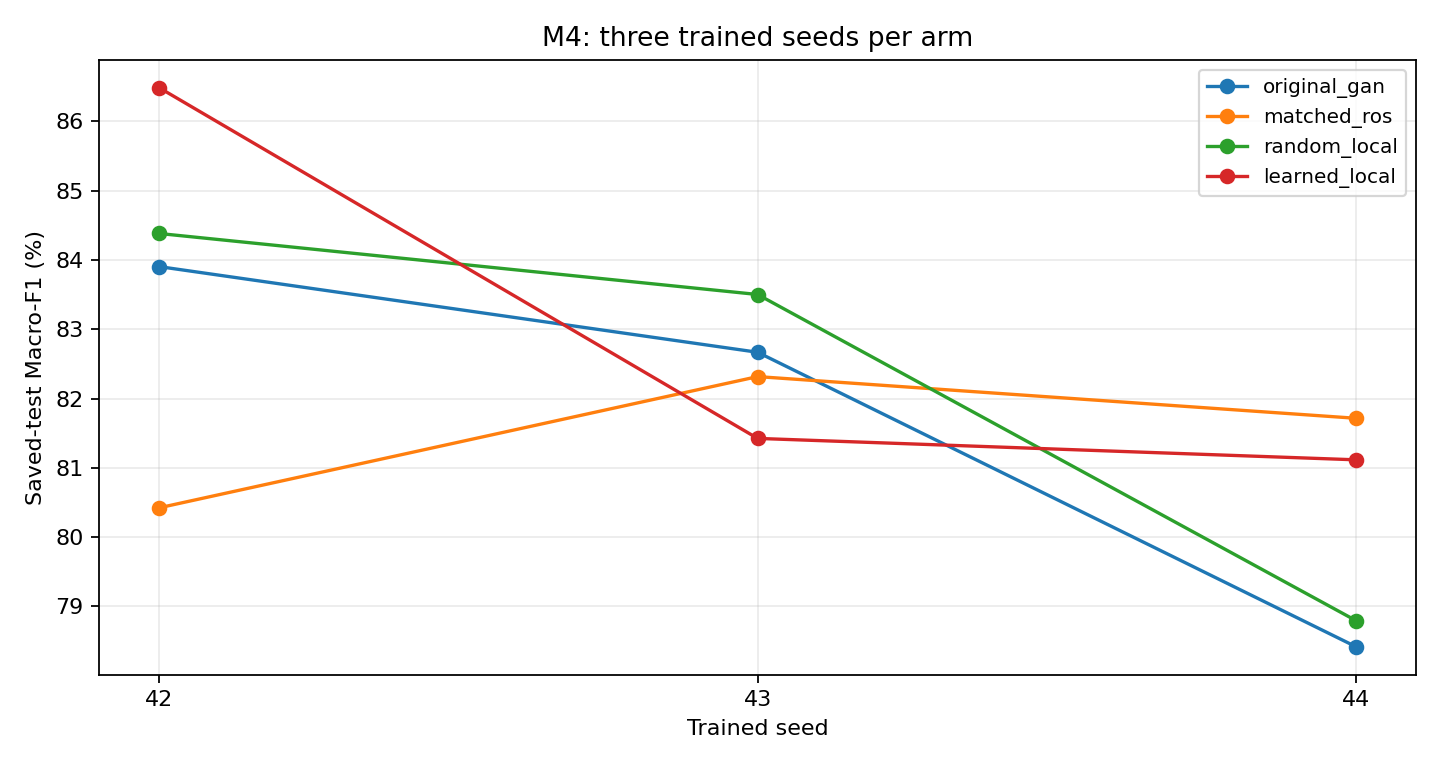

**per_class_mean_f1.png**

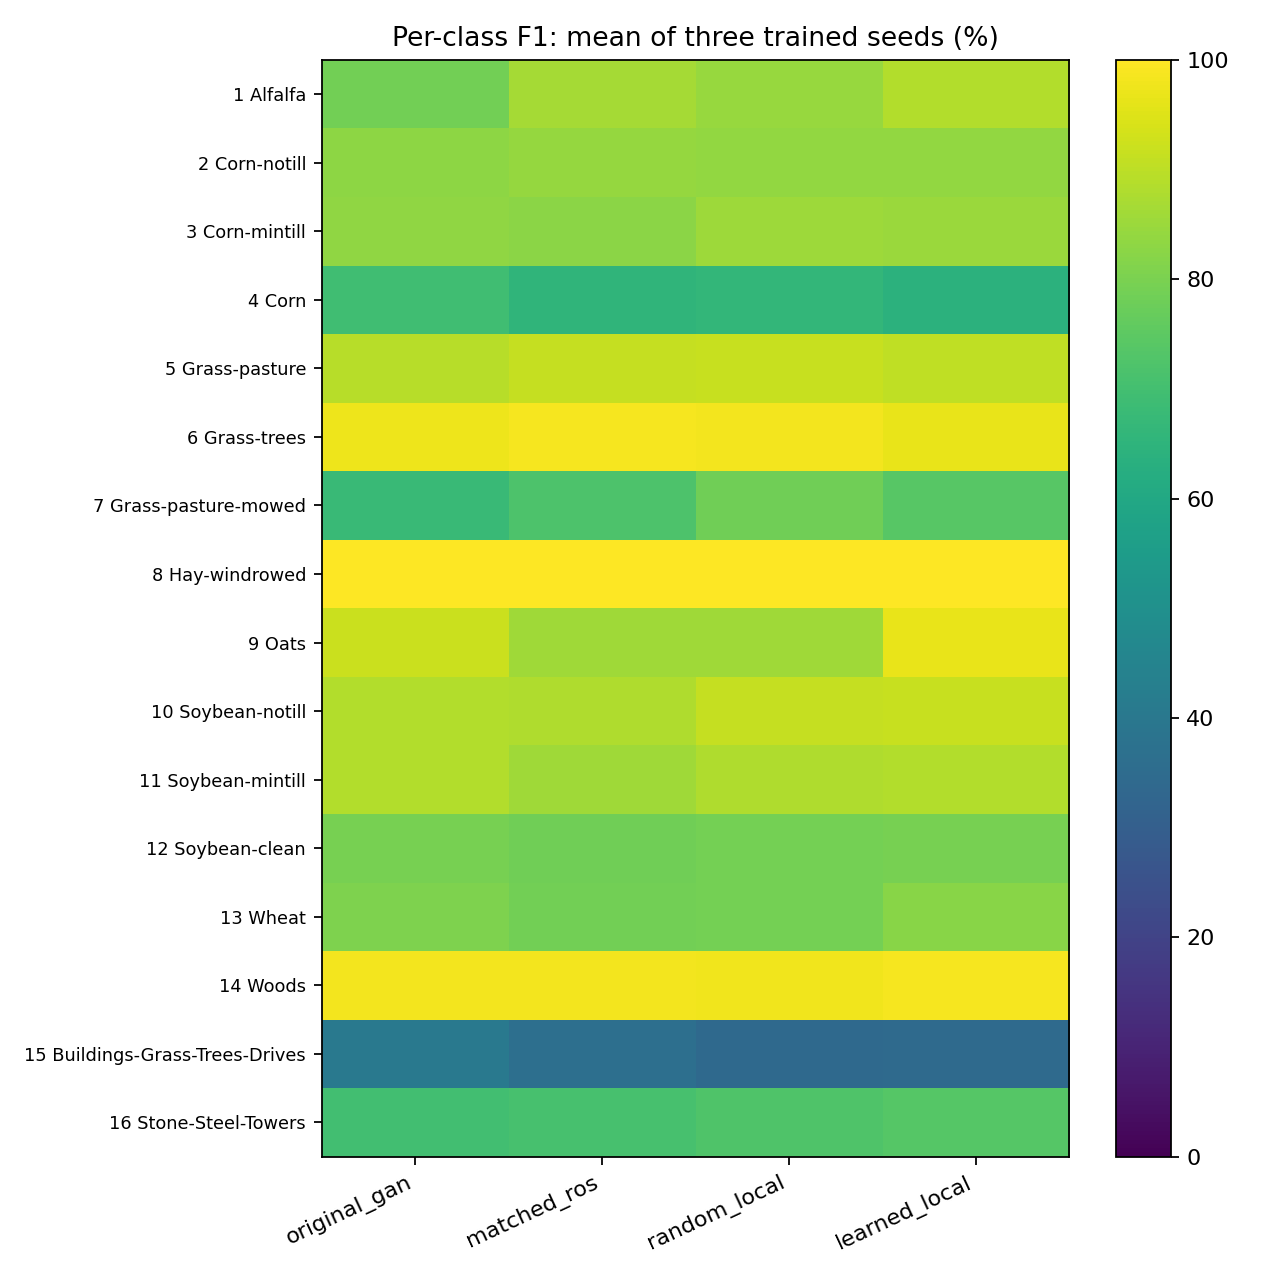

**class_seed_diagnostics.png**

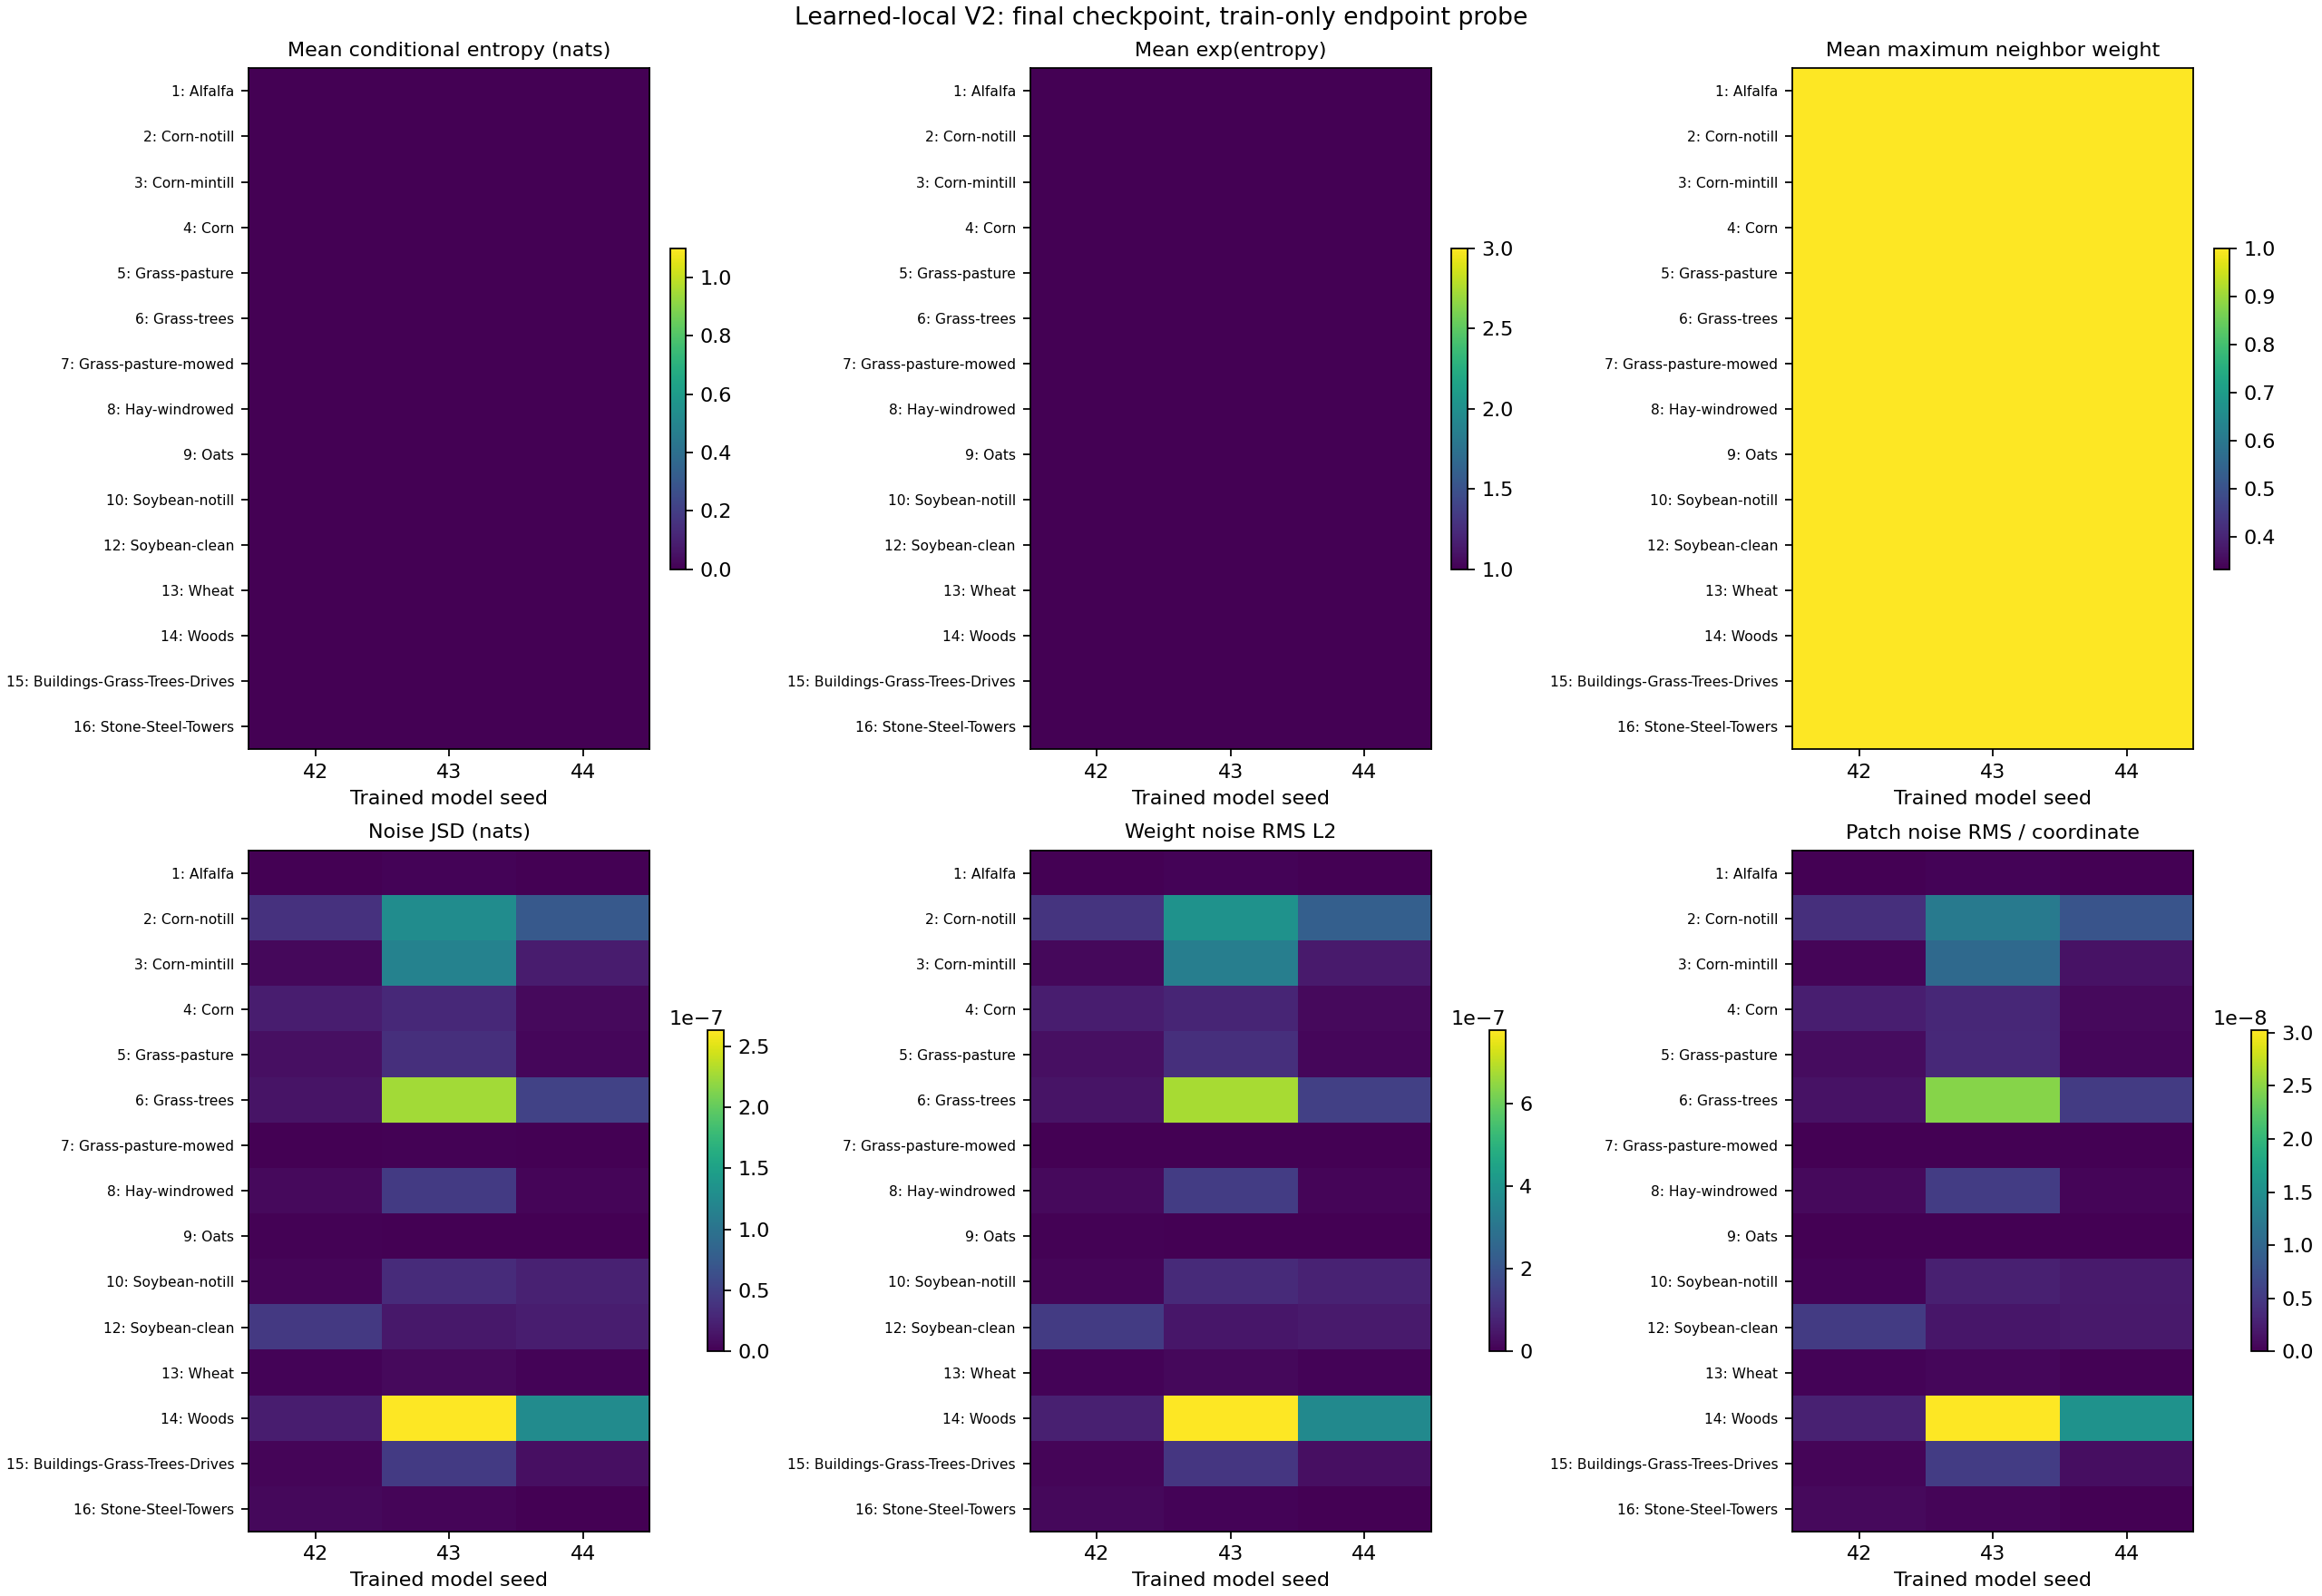

**neighbor_weight_distributions.png**

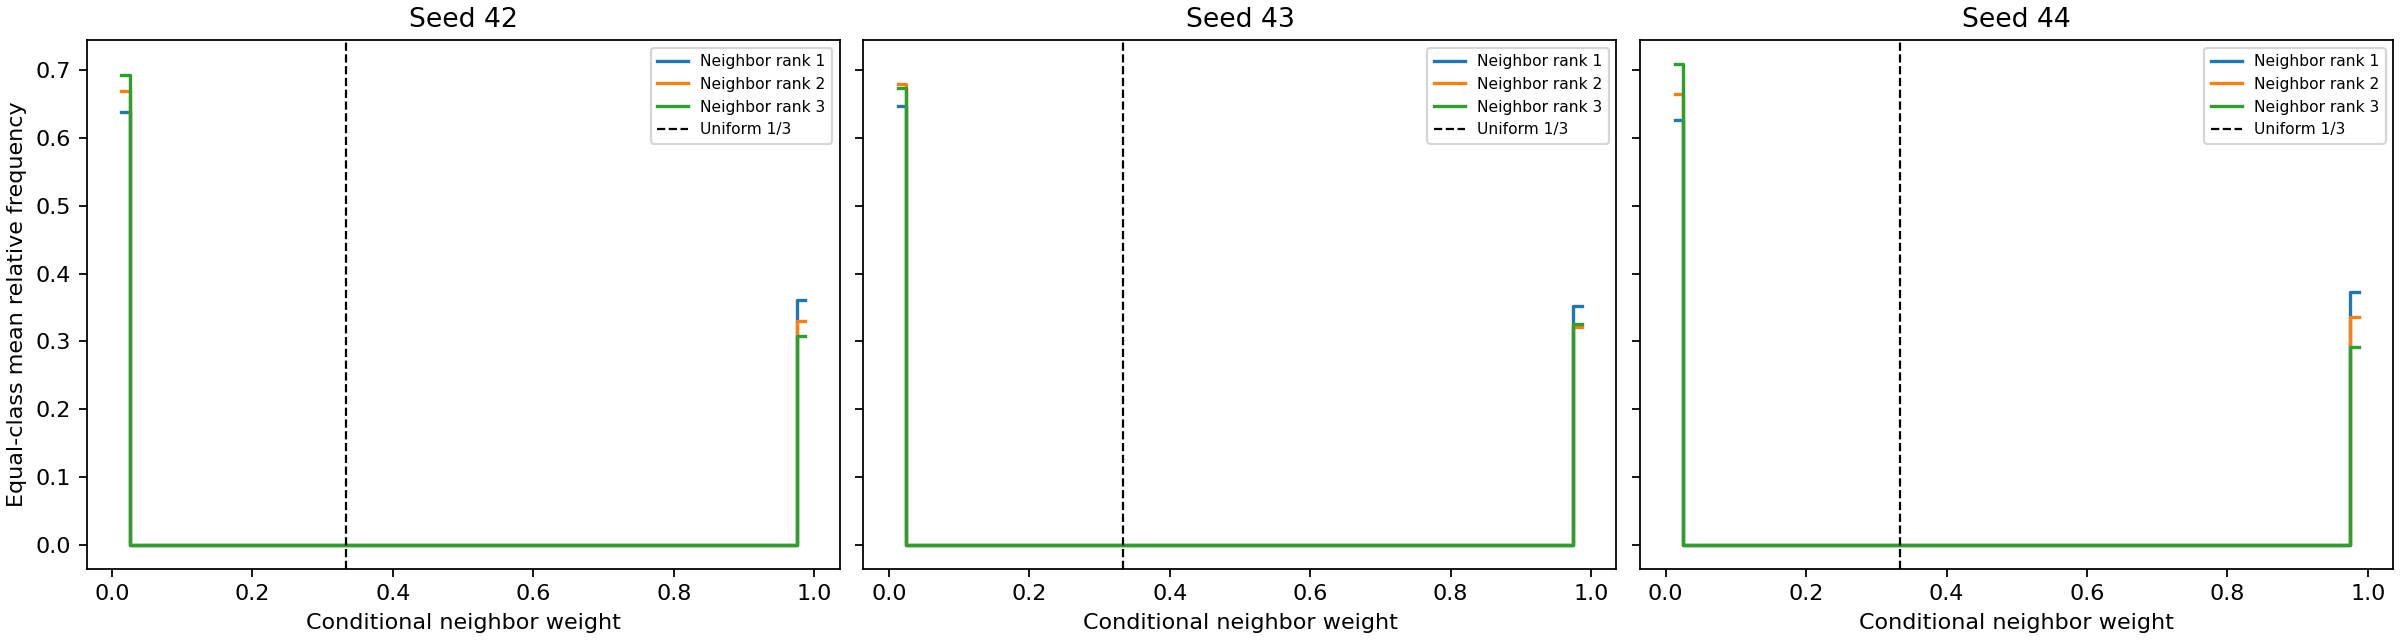

In [8]:
per_class = show_table('test_per_class_mean_sd', 'Kết quả theo lớp — từ predictions gốc', max_rows=70)
figures = sorted((OUTPUT_ROOT / 'saved_results').rglob('*.png'))
print('Hình đã xuất:', len(figures))
for image_path in figures[:4]:
    display(Markdown('**'+image_path.name+'**'))
    display(Image(filename=str(image_path)))

## Phần 6 — Learned Weighting endpoint 8.000: đã có đủ ba seed

Báo cáo gốc lưu actual Dense logits/weights, anchor/neighbor IDs và common noise. Mỗi seed dùng cùng quy tắc anchor/noise; G/heads forward ở inference mode và state không đổi.

Đã quan sát weighting tập trung gần chọn một neighbor và rất ít đổi theo noise. Điều này chưa chứng minh selector vô ích, GAN collapse hoặc nguyên nhân riêng seed 43 kém. Output cũ không lưu toàn bộ intermediate G features; không tự suy ra các feature còn thiếu từ logits.

Giữ raw báo cáo cũ. Các thống kê RMS cực nhỏ phải được diễn giải cùng giới hạn float32; phần 7 dùng phiên bản metric đã sửa mean float64/contrast logits và ghi rõ provenance.

In [9]:
weighting_summary = show_table('weighting_seed_summary', 'Learned weighting — checkpoint 8.000, ba seed')

**Learned weighting — checkpoint 8.000, ba seed**

,model_seed,entropy_mean_nats__mean,effective_neighbors_mean__mean,maximum_weight_mean__mean,noise_jsd_nats__mean,weight_noise_rms_l2__mean,patch_noise_rms_per_coordinate__mean,uniform_displacement_rms_per_coordinate__mean
0,42,2.691301e-07,1.000000,1.0,1.198561e-08,3.623919e-08,1.354356e-09,0.030775
1,43,9.891458e-07,1.000001,1.0,6.359691e-08,1.865500e-07,6.736649e-09,0.030705
2,44,3.537666e-07,1.000000,1.0,2.320989e-08,6.862139e-08,2.496212e-09,0.030777


## Phần 7 — 7.500 → 8.000: chẩn đoán cuối, chưa hoàn tất

**Đây là vị trí mốc 7.500 trong notebook.** M4 đã lưu checkpoint này; không cần train lại. So sánh cần đủ sáu cặp `(seed,updates)` = seed 42/43/44 × 7.500/8.000.

Gắn `03_ENDGAME_LEARNED_LOCAL_6_CKPTS.zip` từ `03_INPUTS` vào Kaggle Input. Nó chứa trực tiếp sáu checkpoint gốc và đúng dữ liệu train/provenance B; không cần mount lại output từ nhiều tài khoản. Nếu giữ `RUN_ENDGAME_TRAIN_ONLY=False`, notebook chỉ ghi PENDING_NOT_RUN.

Nếu bật, tuyến này chạy trong **tiến trình riêng**, dùng source Endgame FIXED, GPU index đã chọn, xác minh metadata/tensor/graph và hash trước/sau. Chỉ G/heads trên train; không C/D/optimizer, validation hoặc test. Không thay rho/k, không thêm kiến trúc fallback, không bỏ seed 42 khi thiếu input. Chưa chạy tuyến này trong lần đóng gói notebook.

In [10]:
ENDGAME_RESULT = {'status':'PENDING_NOT_RUN','reason':'Đủ checkpoint; forward 7.500→8.000 chưa được chạy trong phiên này.'}
if RUN_ENDGAME_TRAIN_ONLY:
    if not Path('/kaggle/working').is_dir():
        raise RuntimeError('Phần 7 dành cho Kaggle GPU. Đường đọc kết quả CPU vẫn dùng được bình thường.')
    optional_files = [p for p in SOURCE_RUNTIME.rglob('*.py') if p.name == 'endgame_optional.py']
    if len(optional_files) != 1:
        raise RuntimeError('Thiếu optional Endgame entrypoint đã đóng gói.')
    relative = optional_files[0].relative_to(SOURCE_RUNTIME).as_posix()
    endgame_module = _load_pinned_module('kltn_endgame_optional',relative)
    ENDGAME_RESULT = endgame_module.run_optional_endgame(
        input_roots=INPUT_ROOTS,
        output_root=OUTPUT_ROOT / '07_ENDGAME_7500_8000',
        gpu_index=ENDGAME_GPU_INDEX,
    )
else:
    print('Phần 7 chưa chạy. Checkpoint 7.500 có sẵn; không train lại.')
(OUTPUT_ROOT / 'endgame_session_status.json').write_text(json.dumps(ENDGAME_RESULT,ensure_ascii=False,indent=2),encoding='utf-8')
display(ENDGAME_RESULT)

Phần 7 chưa chạy. Checkpoint 7.500 có sẵn; không train lại.


{'status': 'PENDING_NOT_RUN',
 'reason': 'Đủ checkpoint; forward 7.500→8.000 chưa được chạy trong phiên này.'}

## Phần 8 — Kết luận và giới hạn

- So sánh M4 báo cả từng seed và trung bình; lợi thế trung bình không đồng nghĩa thắng ổn định mọi seed/lớp hoặc có ý nghĩa thống kê.
- Baseline lịch sử B và đối chứng M4 được tách theo source/runner. Protocol B vẫn có chồng lấn patch trong cùng cảnh; chưa phải kiểm chứng spatial independence.
- Test đã được xem. Phân tích weighting và ý tưởng selector tiếp theo là hậu nghiệm, chưa đủ kết luận quan hệ nhân quả hay tính mới thuật toán.
- Báo cáo Mốc 3 riêng chưa tìm được được ghi vào lịch sử; không coi đó là mất mô hình M4.
- Nearest-one/random-one-fixed và các biến thể k/rho/metric chưa phải kết quả đã có. Notebook này không tự mở lượt train mới.

Cell cuối lưu source/version, trạng thái từng phần và các liên kết tải báo cáo. Các output gốc theo phần được giữ riêng để truy xuất; không sửa checkpoint hoặc ghi đè original report.

In [11]:
final_status = {
    'protocol_B_id':PROTOCOL_B_ID,
    'completed_gpu_phases_locked':COMPLETED_GPU_PHASES_LOCKED,
    'new_training_performed':False,
    'new_test_model_inference_performed':False,
    'saved_result_sections':RESULT['statuses'],
    'endgame_session':ENDGAME_RESULT,
    'source_sha256':{k:v['sha256'] for k,v in EMBEDDED_SOURCE_FILES.items()},
    'report_paths':RESULT.get('paths',{}),
}
(OUTPUT_ROOT / 'master_session_manifest.json').write_text(json.dumps(final_status,ensure_ascii=False,indent=2),encoding='utf-8')
print('HOÀN TẤT đường đọc kết quả đã lưu.')
print('Output:',OUTPUT_ROOT)
for key,path in RESULT.get('paths',{}).items():
    if isinstance(path,str) and Path(path).is_file():
        display(Markdown('**'+key+'**'))
        display(FileLink(path))
display(FileLink(str(OUTPUT_ROOT / 'master_session_manifest.json')))
if not RUN_ENDGAME_TRAIN_ONLY:
    assert 'tensorflow' not in sys.modules, 'Default review unexpectedly initialized TensorFlow.'

HOÀN TẤT đường đọc kết quả đã lưu.
Output: C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z


**report_md**

C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z\saved_results\REPORT.md

**manifest**

C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z\saved_results\review_manifest.json

**report_zip**

C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z\saved_results.zip

C:\Users\ADMIN\OneDrive\Tài liệu\ChatGPT\KLTN\KLTN_clean\outputs\master_reviews\KLTN_MASTER_REVIEW_20261017T042751Z\master_session_manifest.json

In [12]:
import sys
assert 'tensorflow' not in sys.modules, 'Unexpected TensorFlow/model initialization'
print('CPU_ONLY_NO_MODEL_IMPORT_PASS')

CPU_ONLY_NO_MODEL_IMPORT_PASS
